# Projet de Machine Learning — Maintenance prédictive d'un banc hydraulique

**Objectif.** Prédire, pour chaque cycle de production de 60 s, si la condition de la
valve est **optimale (= 100 %)** ou non, à partir de deux capteurs :

| Capteur | Grandeur | Unité | Échantillonnage | Points / cycle |
|---|---|---|---|---|
| PS2 | Pression | bar | 100 Hz | 6000 |
| FS1 | Débit volumique | l/min | 10 Hz | 600 |

et du fichier `profile.txt` (conditions des composants). Les **2000 premiers cycles** servent à
construire le modèle, les **205 derniers** constituent l'échantillon de test final, qui n'est
utilisé qu'une seule fois, à la toute fin.

Plan :
1. Prétraitement des données (chargement, qualité, cible binaire, visualisations, extraction
   et sélection de variables)
2. Modélisation (choix et justification des modèles)
3. Évaluation (validation croisée, matrices de confusion, ROC/AUC, biais/variance)
4. Optimisation des hyperparamètres (Grid Search, Random Search)
5. Test final et interprétation

In [12]:
from __future__ import annotations


In [13]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import (AdaBoostClassifier, GradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier)
from sklearn.feature_selection import (SelectKBest, VarianceThreshold, f_classif,
                                       mutual_info_classif)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_predict,
                                     cross_validate, learning_curve)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 140)

# Dossier où sont enregistrées les figures et tables utilisées par le rapport LaTeX
REPORT_DIR = Path("../rapport") if Path("../rapport").exists() else Path("rapport")
FIG_DIR, TAB_DIR = REPORT_DIR / "figures", REPORT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True); TAB_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

RESULTS = {}  # chiffres clés exportés vers le rapport (rapport/tables/resultats.tex)

## 1. Prétraitement des données

### 1.1 Chargement

Les fonctions ci-dessous cherchent les fichiers `PS2.txt`, `FS1.txt` et `profile.txt` dans
`./data`, `../data`, `../Projet_ML`… ou dans le dossier indiqué par la variable
d'environnement `VALVE_DATA_DIR`. Sous Colab, déposez les trois fichiers dans `/content/data`.

In [14]:
"""Chargement des données brutes du banc hydraulique (UCI, Helwig et al. 2015).

Seuls les trois fichiers autorisés par les consignes sont utilisés :
PS2.txt (pression, 100 Hz), FS1.txt (débit, 10 Hz) et profile.txt (conditions).
"""

import os
from pathlib import Path

import numpy as np
import pandas as pd

PROFILE_COLUMNS = ["cooler", "valve", "pump", "accumulator", "stable"]
N_TRAIN = 2000  # les 2000 premiers cycles servent à construire le modèle

# Dossiers explorés (dans l'ordre) pour trouver les fichiers .txt
_CANDIDATES = [
    os.environ.get("VALVE_DATA_DIR", ""),
    "data",
    "../data",
    "../Projet_ML",
    "../../Projet_ML",
    "Projet_ML",
    "/mnt/project-files/Projet_ML",
    "/content/data",  # Google Colab
]


def find_data_dir(required=("PS2.txt", "FS1.txt", "profile.txt")) -> Path:
    """Renvoie le premier dossier candidat contenant tous les fichiers requis."""
    for cand in _CANDIDATES:
        if cand and all((Path(cand) / f).exists() for f in required):
            return Path(cand).resolve()
    raise FileNotFoundError(
        f"Impossible de trouver {required}. Placez les fichiers dans ./data "
        "ou définissez la variable d'environnement VALVE_DATA_DIR."
    )


def load_sensor(path: str | Path) -> np.ndarray:
    """Charge une matrice capteur (lignes = cycles, colonnes = points du cycle)."""
    return pd.read_csv(path, sep="\t", header=None).to_numpy(dtype=float)


def load_profile(path: str | Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep="\t", header=None, names=PROFILE_COLUMNS)
    df.index = pd.RangeIndex(1, len(df) + 1, name="cycle")
    return df


def make_target(profile: pd.DataFrame) -> pd.Series:
    """Cible binaire : 1 si la valve est optimale (=100 %), 0 sinon."""
    return (profile["valve"] == 100).astype(int).rename("valve_optimal")


def load_all(data_dir: str | Path | None = None):
    """Charge PS2, FS1 et profile. Renvoie (ps2, fs1, profile)."""
    data_dir = Path(data_dir) if data_dir else find_data_dir()
    ps2 = load_sensor(data_dir / "PS2.txt")
    fs1 = load_sensor(data_dir / "FS1.txt")
    profile = load_profile(data_dir / "profile.txt")
    if not (len(ps2) == len(fs1) == len(profile)):
        raise ValueError("Les fichiers n'ont pas le même nombre de cycles.")
    return ps2, fs1, profile


def train_test_split_by_cycle(X, y, n_train: int = N_TRAIN):
    """Découpage imposé : les n_train premiers cycles / le reste (test final)."""
    return X.iloc[:n_train], X.iloc[n_train:], y.iloc[:n_train], y.iloc[n_train:]

In [15]:
DATA_DIR = find_data_dir()
print("Données lues dans :", DATA_DIR)
t0 = time.time()
ps2, fs1, profile = load_all(DATA_DIR)
print(f"Chargement en {time.time()-t0:.1f} s")
print("PS2     :", ps2.shape, "(cycles x points à 100 Hz)")
print("FS1     :", fs1.shape, "(cycles x points à 10 Hz)")
print("profile :", profile.shape)
profile.head()

Données lues dans : /Users/naher/Documents/projet_ml 2/data
Chargement en 0.9 s
PS2     : (2205, 6000) (cycles x points à 100 Hz)
FS1     : (2205, 600) (cycles x points à 10 Hz)
profile : (2205, 5)


,cooler,valve,pump,accumulator,stable
cycle,,,,,
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1
5,3,100,0,130,1


### 1.2 Statistiques descriptives

In [16]:
def describe_signal(x, name, unit):
    flat = x.ravel()
    per_cycle_mean = x.mean(axis=1)
    return pd.Series({
        "capteur": name, "unité": unit, "cycles": x.shape[0], "points/cycle": x.shape[1],
        "min": flat.min(), "max": flat.max(), "moyenne": flat.mean(), "écart-type": flat.std(),
        "médiane": np.median(flat),
        "écart-type des moyennes par cycle": per_cycle_mean.std(),
    })

desc = pd.DataFrame([describe_signal(ps2, "PS2", "bar"), describe_signal(fs1, "FS1", "l/min")]).set_index("capteur")
desc

,unité,cycles,points/cycle,min,max,moyenne,écart-type,médiane,écart-type des moyennes par cycle
capteur,,,,,,,,,
PS2,bar,2205,6000,0.0,167.770,109.379906,48.103172,125.700,4.985455
FS1,l/min,2205,600,0.0,20.479,6.198549,3.213826,7.641,1.032649


In [17]:
profile.describe().T

,count,mean,std,min,25%,50%,75%,max
cooler,2205.0,41.240816,42.383143,3.0,3.0,20.0,100.0,100.0
valve,2205.0,90.693878,10.681802,73.0,80.0,100.0,100.0,100.0
pump,2205.0,0.669388,0.817233,0.0,0.0,0.0,1.0,2.0
accumulator,2205.0,107.199546,16.435848,90.0,90.0,100.0,130.0,130.0
stable,2205.0,0.342857,0.474772,0.0,0.0,0.0,1.0,1.0


In [18]:
for col in profile.columns:
    print(col, profile[col].value_counts().sort_index().to_dict())

cooler {3: 732, 20: 732, 100: 741}
valve {73: 360, 80: 360, 90: 360, 100: 1125}
pump {0: 1221, 1: 492, 2: 492}
accumulator {90: 808, 100: 399, 115: 399, 130: 599}
stable {0: 1449, 1: 756}


### 1.3 Valeurs manquantes et valeurs aberrantes

On vérifie : valeurs manquantes (`NaN`), valeurs infinies, valeurs physiquement impossibles
(pression ou débit négatifs), cycles constants (capteur figé), puis on recherche des cycles
atypiques avec la règle de l'IQR (1,5 × écart interquartile) et le z-score robuste sur des
statistiques par cycle.

In [19]:
quality = pd.DataFrame({
    "NaN": [np.isnan(ps2).sum(), np.isnan(fs1).sum(), profile.isna().sum().sum()],
    "inf": [np.isinf(ps2).sum(), np.isinf(fs1).sum(), 0],
    "valeurs < 0": [(ps2 < 0).sum(), (fs1 < 0).sum(), (profile < 0).sum().sum()],
    "cycles constants": [(ps2.std(axis=1) == 0).sum(), (fs1.std(axis=1) == 0).sum(), np.nan],
    "lignes dupliquées": [pd.DataFrame(ps2).duplicated().sum(), pd.DataFrame(fs1).duplicated().sum(), np.nan],
}, index=["PS2", "FS1", "profile"])
quality

,NaN,inf,valeurs < 0,cycles constants,lignes dupliquées
PS2,0,0,0,0.0,0.0
FS1,0,0,0,0.0,0.0
profile,0,0,0,NaN,NaN


In [20]:
def iqr_outliers(v):
    q1, q3 = np.percentile(v, [25, 75]); iqr = q3 - q1
    return (v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)

def robust_z(v):
    med = np.median(v); mad = np.median(np.abs(v - med)) * 1.4826
    return (v - med) / (mad + 1e-12)

cycle_stats = pd.DataFrame({
    "PS2_mean": ps2.mean(axis=1), "PS2_std": ps2.std(axis=1), "PS2_max": ps2.max(axis=1),
    "FS1_mean": fs1.mean(axis=1), "FS1_std": fs1.std(axis=1), "FS1_max": fs1.max(axis=1),
}, index=profile.index)
out_iqr = cycle_stats.apply(iqr_outliers)
out_z = cycle_stats.apply(lambda c: np.abs(robust_z(c.values)) > 3.5)
outlier_summary = pd.DataFrame({"IQR (1,5)": out_iqr.sum(), "|z robuste| > 3,5": out_z.sum()})
display(outlier_summary)
any_out = out_iqr.any(axis=1)
print(f"Cycles signalés par au moins un critère IQR : {any_out.sum()} ({any_out.mean():.1%})")
print("Répartition de ces cycles selon la condition de la valve :")
print(profile.loc[any_out, "valve"].value_counts().sort_index().to_dict())
print("Répartition selon la condition du refroidisseur :")
print(profile.loc[any_out, "cooler"].value_counts().sort_index().to_dict())
RESULTS["nOutlierCycles"] = int(any_out.sum())

,"IQR (1,5)","|z robuste| > 3,5"
PS2_mean,240,240
PS2_std,240,240
PS2_max,46,39
FS1_mean,240,240
FS1_std,250,238
FS1_max,42,447


Cycles signalés par au moins un critère IQR : 331 (15.0%)
Répartition de ces cycles selon la condition de la valve :
{73: 75, 80: 64, 90: 64, 100: 128}
Répartition selon la condition du refroidisseur :
{3: 295, 100: 36}


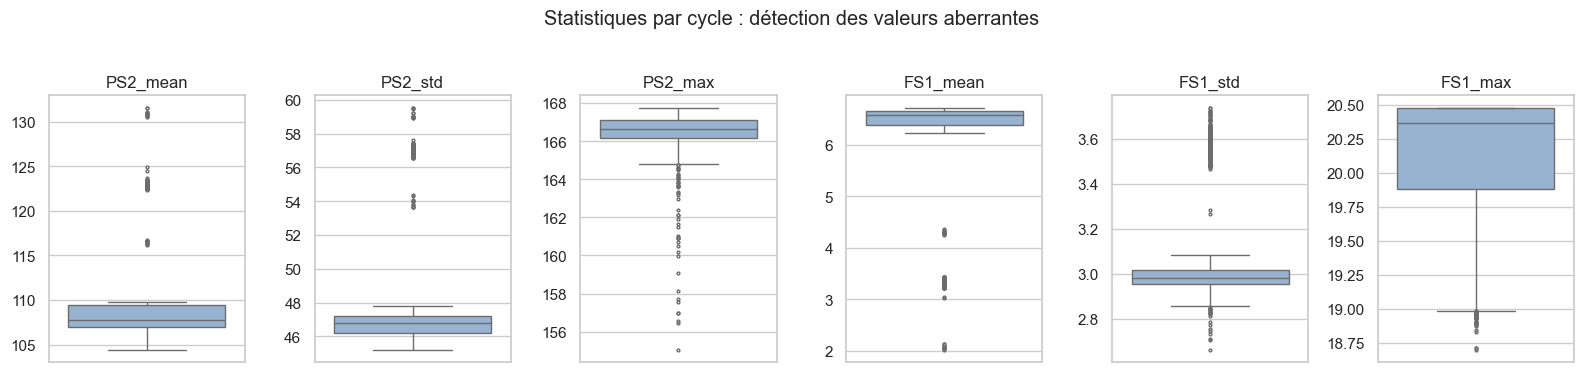

In [21]:
fig, axes = plt.subplots(1, 6, figsize=(16, 3.6))
for ax, col in zip(axes, cycle_stats.columns):
    sns.boxplot(y=cycle_stats[col], ax=ax, color="#8fb3d9", fliersize=2)
    ax.set_title(col); ax.set_ylabel("")
plt.suptitle("Statistiques par cycle : détection des valeurs aberrantes", y=1.03)
plt.tight_layout(); savefig("boxplots_cycles_bruts"); plt.show()

**Décision.** Les cycles « aberrants » au sens statistique ne sont pas des erreurs de mesure :
ils correspondent à des états physiques réels du banc (refroidisseur proche de la panne,
accumulateur dégradé, régime transitoire…). Les supprimer ferait disparaître justement les
situations que la maintenance prédictive doit reconnaître, et le jeu de test contiendra
des cycles de ce type. On les **conserve** et l'on limite leur influence par la
standardisation et par le choix de modèles robustes (arbres, ensembles). Aucune valeur
manquante n'est à imputer.

### 1.4 Encodage des variables catégorielles

Les capteurs fournissent uniquement des variables **continues**. Les colonnes de
`profile.txt` sont des niveaux numériques ordonnés (variables ordinales) ; elles ne servent
pas de variables explicatives (ce sont des étiquettes d'état mesurées hors ligne, inconnues
en production), sauf `valve` qui définit la cible. Aucun encodage one-hot n'est donc
nécessaire ; la seule transformation est la **binarisation de la cible**.

### 1.5 Transformation en classification binaire et équilibre des classes

,Total,Entraînement (1-2000),Test (2001-2205)
valve_optimal,,,
non optimale (0),1080,948,132
optimale (1),1125,1052,73


,Total,Entraînement (1-2000),Test (2001-2205)
valve_optimal,,,
non optimale (0),49.0,47.4,64.4
optimale (1),51.0,52.6,35.6


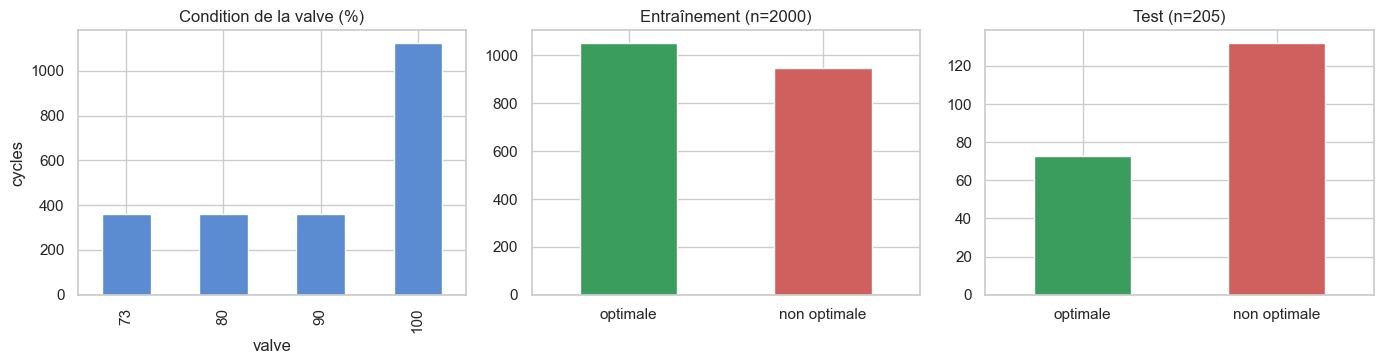

In [22]:
y = make_target(profile)
y_train, y_test = y.iloc[:N_TRAIN], y.iloc[N_TRAIN:]

dist = pd.DataFrame({
    "Total": y.value_counts(), "Entraînement (1-2000)": y_train.value_counts(),
    "Test (2001-2205)": y_test.value_counts(),
}).rename(index={1: "optimale (1)", 0: "non optimale (0)"})
dist_pct = (dist / dist.sum() * 100).round(1)
display(dist); display(dist_pct)
RESULTS.update(trainPosPct=dist_pct.iloc[:, 1]["optimale (1)"], testPosPct=dist_pct.iloc[:, 2]["optimale (1)"],
               nTest=len(y_test), nTestPos=int(y_test.sum()))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
profile["valve"].value_counts().sort_index().plot.bar(ax=axes[0], color="#5b8bd0")
axes[0].set_title("Condition de la valve (%)"); axes[0].set_xlabel("valve"); axes[0].set_ylabel("cycles")
for ax, (name, s) in zip(axes[1:], [("Entraînement", y_train), ("Test", y_test)]):
    s.map({1: "optimale", 0: "non optimale"}).value_counts().reindex(["optimale", "non optimale"]).plot.bar(ax=ax, color=["#3a9d5d", "#d0605e"])
    ax.set_title(f"{name} (n={len(s)})"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("distribution_classes"); plt.show()

Le jeu d'entraînement est **quasiment équilibré** (≈ 53 % / 47 %) : il n'est pas nécessaire de
rééchantillonner. On utilisera tout de même une validation croisée **stratifiée** et on
suivra le F1-score et l'AUC en plus de l'accuracy. Le jeu de test est en revanche
déséquilibré dans l'autre sens (≈ 36 % de cycles optimaux) : l'accuracy y sera moins
informative que la précision, le rappel et l'AUC.

Il faut aussi noter que le découpage est **temporel** (cycles 1-2000 / 2001-2205) et que
les conditions des autres composants changent au fil de l'expérience :

In [23]:
comp = pd.concat({"Entraînement": profile.iloc[:N_TRAIN], "Test": profile.iloc[N_TRAIN:]}, names=["jeu"])
for col in ["cooler", "pump", "accumulator", "stable"]:
    display(pd.crosstab(comp.index.get_level_values(0), comp[col], normalize="index").round(3).rename_axis(index="jeu", columns=col))

cooler,3,20,100
jeu,,,
Entraînement,0.366,0.366,0.268
Test,0.000,0.000,1.000


pump,0,1,2
jeu,,,
Entraînement,0.560,0.214,0.226
Test,0.493,0.307,0.200


accumulator,90,100,115,130
jeu,,,,
Entraînement,0.333,0.168,0.2,0.3
Test,0.693,0.307,0.0,0.0


stable,0,1
jeu,,
Entraînement,0.629,0.371
Test,0.932,0.068


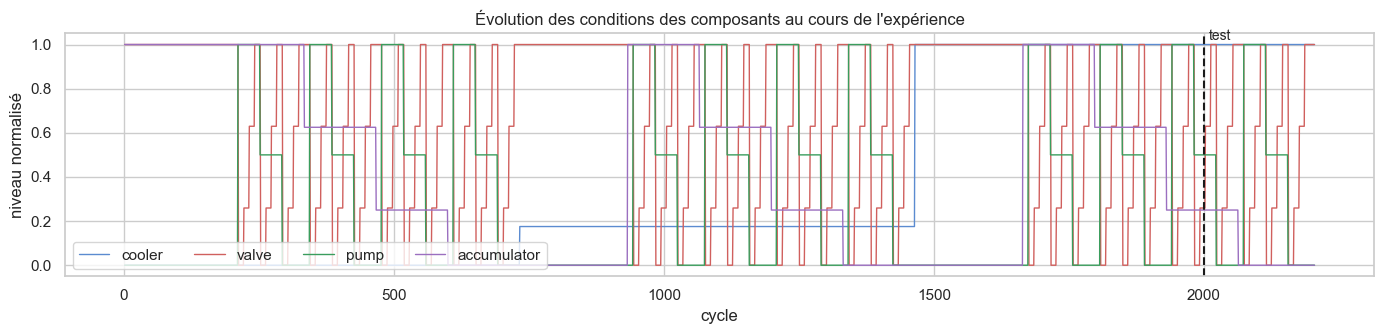

In [24]:
fig, ax = plt.subplots(figsize=(14, 3.5))
for col, c in zip(["cooler", "valve", "pump", "accumulator"], ["#5b8bd0", "#d0605e", "#3a9d5d", "#9b6fc0"]):
    v = profile[col]; ax.plot(profile.index, (v - v.min()) / (v.max() - v.min()), label=col, lw=1, color=c)
ax.axvline(N_TRAIN + 0.5, color="k", ls="--"); ax.text(N_TRAIN + 10, 1.02, "test", fontsize=10)
ax.set_xlabel("cycle"); ax.set_ylabel("niveau normalisé"); ax.legend(ncol=4, loc="lower left")
ax.set_title("Évolution des conditions des composants au cours de l'expérience")
plt.tight_layout(); savefig("conditions_temporelles"); plt.show()

### 1.6 Visualisation des signaux bruts

On compare le profil moyen d'un cycle selon la condition de la valve. Un retard de
commutation doit se traduire par un **décalage temporel** et une modification des
transitoires de pression et de débit.

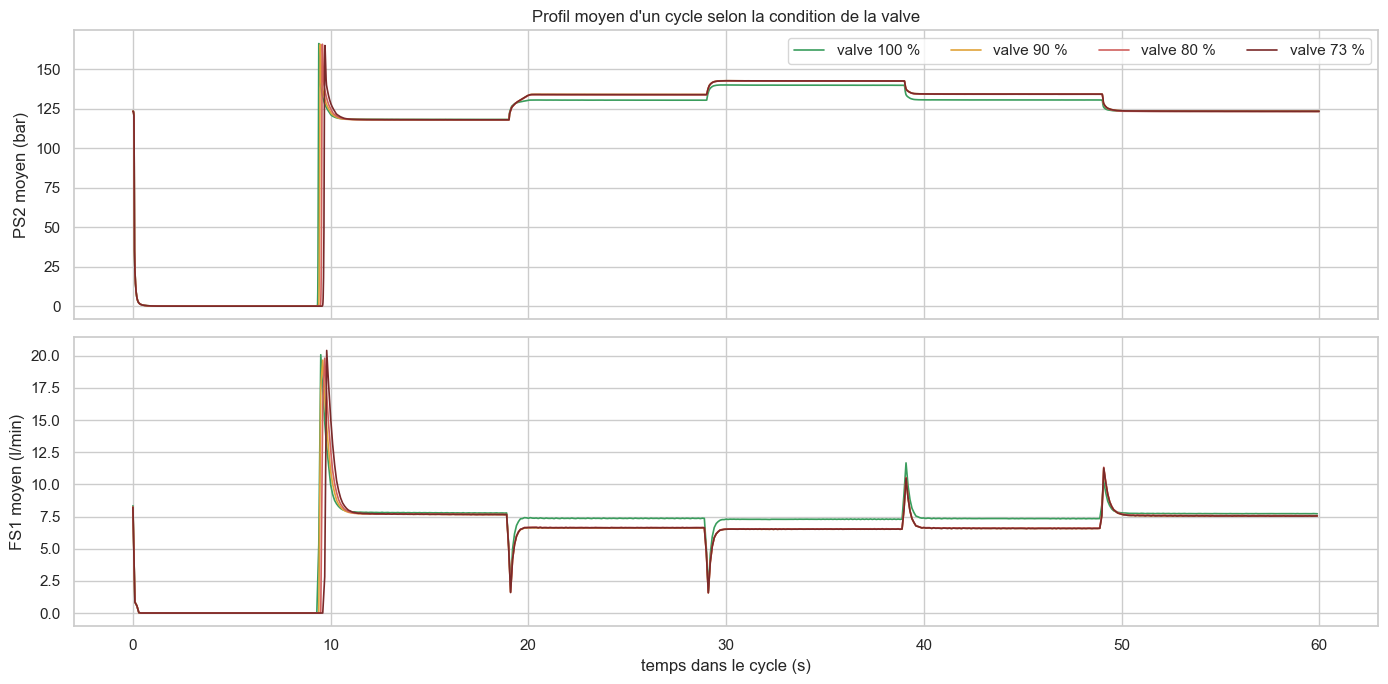

In [25]:
t_ps2 = np.arange(ps2.shape[1]) / 100.0
t_fs1 = np.arange(fs1.shape[1]) / 10.0
palette = {100: "#3a9d5d", 90: "#e0a33a", 80: "#d0605e", 73: "#7a2a2a"}
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for lvl in [100, 90, 80, 73]:
    m = (profile["valve"] == lvl).values
    axes[0].plot(t_ps2, ps2[m].mean(axis=0), color=palette[lvl], lw=1.2, label=f"valve {lvl} %")
    axes[1].plot(t_fs1, fs1[m].mean(axis=0), color=palette[lvl], lw=1.2, label=f"valve {lvl} %")
axes[0].set_ylabel("PS2 moyen (bar)"); axes[1].set_ylabel("FS1 moyen (l/min)"); axes[1].set_xlabel("temps dans le cycle (s)")
axes[0].legend(ncol=4); axes[0].set_title("Profil moyen d'un cycle selon la condition de la valve")
plt.tight_layout(); savefig("signaux_moyens_par_valve"); plt.show()

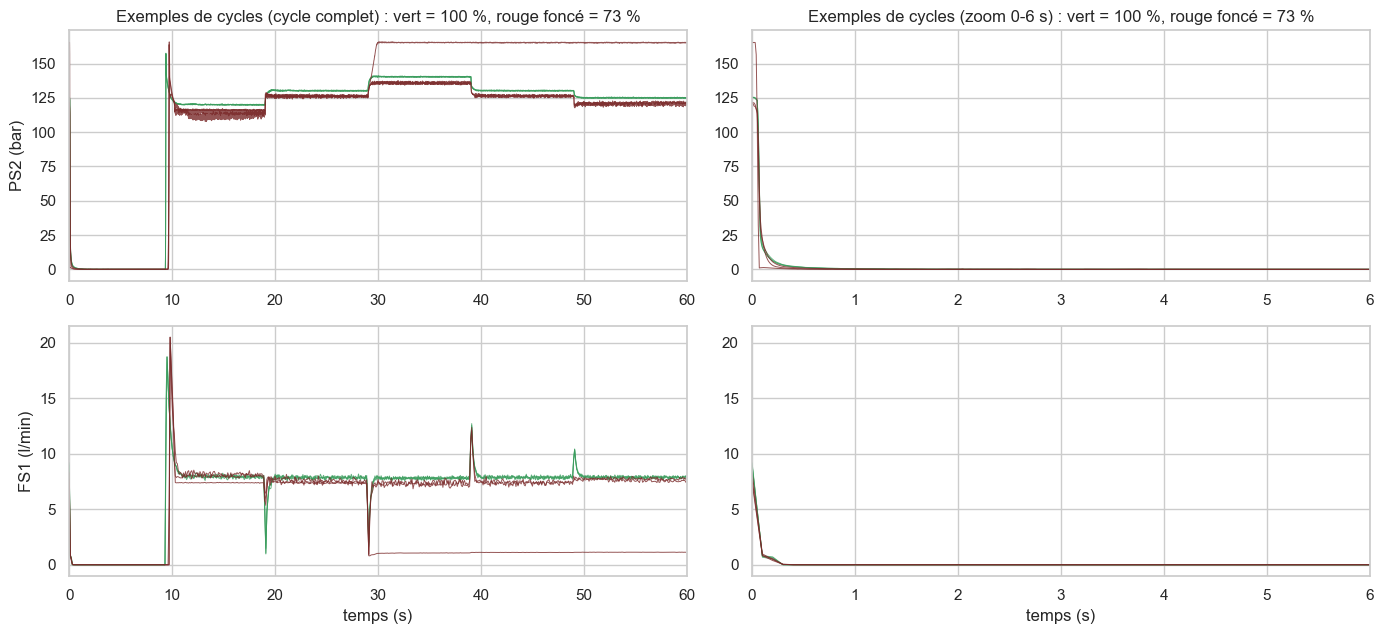

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5))
for j, (zoom, title) in enumerate([((0, 60), "cycle complet"), ((0, 6), "zoom 0-6 s")]):
    for lvl in [100, 73]:
        idx = np.where(profile["valve"] == lvl)[0][:3]
        for i in idx:
            axes[0, j].plot(t_ps2, ps2[i], color=palette[lvl], lw=0.7, alpha=0.8)
            axes[1, j].plot(t_fs1, fs1[i], color=palette[lvl], lw=0.7, alpha=0.8)
    for a in axes[:, j]: a.set_xlim(*zoom)
    axes[0, j].set_title(f"Exemples de cycles ({title}) : vert = 100 %, rouge foncé = 73 %")
axes[0, 0].set_ylabel("PS2 (bar)"); axes[1, 0].set_ylabel("FS1 (l/min)")
axes[1, 0].set_xlabel("temps (s)"); axes[1, 1].set_xlabel("temps (s)")
plt.tight_layout(); savefig("exemples_cycles"); plt.show()

### 1.7 Extraction de caractéristiques

Les 6600 points bruts d'un cycle sont très redondants (points voisins quasi identiques) et
peu adaptés à des modèles comme k-NN, Naive Bayes ou un arbre unique. On résume chaque
signal par des **descripteurs physiques interprétables** :

* statistiques globales : moyenne, écart-type, min, max, quantiles, IQR, amplitude, RMS,
  asymétrie, aplatissement, instants du maximum et du minimum ;
* statistiques de la **dérivée** (vitesse de variation, raideur des transitoires) ;
* moyennes et écarts-types sur **10 fenêtres temporelles** de 6 s (le retard de la valve
  décale les phases du cycle) ;
* répartition de l'**énergie spectrale** dans 4 bandes de fréquence.

In [27]:
"""Extraction de caractéristiques par cycle à partir des signaux bruts.

Chaque cycle dure 60 s : PS2 contient 6000 points (100 Hz) et FS1 600 points
(10 Hz). Un modèle classique ne peut pas exploiter directement 6600 colonnes
fortement corrélées ; on résume donc chaque signal par des statistiques
globales, des statistiques sur sa dérivée, des moyennes par fenêtre temporelle
(le retard de commutation de la valve décale les transitoires dans le temps)
et l'énergie dans quelques bandes de fréquence.
"""

import numpy as np
import pandas as pd
from scipy import stats

N_WINDOWS = 10
N_BANDS = 4


def _global_stats(x: np.ndarray) -> dict[str, np.ndarray]:
    q05, q25, q50, q75, q95 = np.percentile(x, [5, 25, 50, 75, 95], axis=1)
    return {
        "mean": x.mean(axis=1),
        "std": x.std(axis=1),
        "min": x.min(axis=1),
        "max": x.max(axis=1),
        "median": q50,
        "q05": q05,
        "q25": q25,
        "q75": q75,
        "q95": q95,
        "iqr": q75 - q25,
        "ptp": x.max(axis=1) - x.min(axis=1),
        "rms": np.sqrt((x ** 2).mean(axis=1)),
        "skew": np.nan_to_num(stats.skew(x, axis=1)),
        "kurtosis": np.nan_to_num(stats.kurtosis(x, axis=1)),
        "argmax_s": x.argmax(axis=1) / x.shape[1] * 60.0,
        "argmin_s": x.argmin(axis=1) / x.shape[1] * 60.0,
    }


def _derivative_stats(x: np.ndarray, fs: float) -> dict[str, np.ndarray]:
    d = np.diff(x, axis=1) * fs  # unité / s
    return {
        "d_absmean": np.abs(d).mean(axis=1),
        "d_std": d.std(axis=1),
        "d_max": d.max(axis=1),
        "d_min": d.min(axis=1),
    }


def _window_stats(x: np.ndarray, n_windows: int) -> dict[str, np.ndarray]:
    out = {}
    for i, w in enumerate(np.array_split(x, n_windows, axis=1)):
        out[f"w{i}_mean"] = w.mean(axis=1)
        out[f"w{i}_std"] = w.std(axis=1)
    return out


def _spectral_stats(x: np.ndarray, n_bands: int) -> dict[str, np.ndarray]:
    xc = x - x.mean(axis=1, keepdims=True)
    power = np.abs(np.fft.rfft(xc, axis=1)) ** 2
    power = power[:, 1:]  # on enlève la composante continue
    total = power.sum(axis=1) + 1e-12
    # bandes logarithmiques : les basses fréquences portent l'essentiel
    n = power.shape[1]
    inner = np.geomspace(1, n, n_bands + 1).astype(int)[1:-1]
    edges = np.unique(np.r_[0, inner, n])
    out = {}
    for i in range(len(edges) - 1):
        out[f"band{i}_ratio"] = power[:, edges[i]:edges[i + 1]].sum(axis=1) / total
    out["spec_log_energy"] = np.log1p(total)
    return out


def extract_signal_features(x: np.ndarray, name: str, fs: float,
                            n_windows: int = N_WINDOWS,
                            n_bands: int = N_BANDS) -> pd.DataFrame:
    """Calcule toutes les caractéristiques d'un capteur (matrice cycles x points)."""
    x = np.asarray(x, dtype=float)
    if x.ndim == 1:
        x = x[None, :]
    feats = {}
    feats.update(_global_stats(x))
    feats.update(_derivative_stats(x, fs))
    feats.update(_window_stats(x, n_windows))
    feats.update(_spectral_stats(x, n_bands))
    df = pd.DataFrame(feats)
    df.columns = [f"{name}_{c}" for c in df.columns]
    return df


def build_feature_matrix(ps2: np.ndarray, fs1: np.ndarray) -> pd.DataFrame:
    """Matrice de caractéristiques complète (une ligne par cycle)."""
    X = pd.concat(
        [
            extract_signal_features(ps2, "PS2", fs=100.0),
            extract_signal_features(fs1, "FS1", fs=10.0),
        ],
        axis=1,
    )
    X.index = pd.RangeIndex(1, len(X) + 1, name="cycle")
    return X

In [28]:
t0 = time.time()
X = build_feature_matrix(ps2, fs1)
print(f"Matrice de caractéristiques : {X.shape} en {time.time()-t0:.1f} s")
print("NaN :", X.isna().sum().sum(), "| inf :", np.isinf(X.values).sum())
X_train, X_test = X.iloc[:N_TRAIN], X.iloc[N_TRAIN:]
RESULTS["nFeatures"] = X.shape[1]
X.head()

Matrice de caractéristiques : (2205, 90) en 1.4 s
NaN : 0 | inf : 0


,PS2_mean,PS2_std,PS2_min,PS2_max,PS2_median,PS2_q05,PS2_q25,PS2_q75,PS2_q95,PS2_iqr,PS2_ptp,PS2_rms,PS2_skew,PS2_kurtosis,PS2_argmax_s,PS2_argmin_s,PS2_d_absmean,PS2_d_std,PS2_d_max,PS2_d_min,PS2_w0_mean,PS2_w0_std,PS2_w1_mean,PS2_w1_std,PS2_w2_mean,...,FS1_w0_mean,FS1_w0_std,FS1_w1_mean,FS1_w1_std,FS1_w2_mean,FS1_w2_std,FS1_w3_mean,FS1_w3_std,FS1_w4_mean,FS1_w4_std,FS1_w5_mean,FS1_w5_std,FS1_w6_mean,FS1_w6_std,FS1_w7_mean,FS1_w7_std,FS1_w8_mean,FS1_w8_std,FS1_w9_mean,FS1_w9_std,FS1_band0_ratio,FS1_band1_ratio,FS1_band2_ratio,FS1_band3_ratio,FS1_spec_log_energy
cycle,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,109.466914,47.110581,0.0,156.99,129.365,0.0,120.1900,130.54,140.59,10.3500,156.99,119.173873,-1.837853,1.508854,9.39,1.85,11.713419,139.121437,6208.6,-4751.0,2.013145,13.380887,54.063957,61.198944,120.131650,...,0.174633,1.154660,4.280533,5.264573,7.921367,0.099160,7.562167,1.016250,7.583383,0.966105,7.788867,0.106834,8.059100,0.796658,7.857767,0.126316,8.002300,0.443983,7.868033,0.101200,0.718289,0.142591,0.101679,0.037440,14.306565
2,109.354890,47.041690,0.0,157.56,129.385,0.0,120.1300,130.38,140.46,10.2500,157.56,119.043743,-1.838351,1.511086,9.39,2.22,12.019503,136.437402,6195.3,-3994.3,2.088667,13.448354,54.106220,61.239739,120.060067,...,0.175483,1.146503,4.201483,5.137875,7.945283,0.116181,7.577767,1.055732,7.590017,0.955063,7.816867,0.105890,8.076400,0.829698,7.870617,0.109630,8.012333,0.431575,7.886900,0.090932,0.729294,0.140220,0.097241,0.033246,14.300458
3,109.158845,46.988144,0.0,156.97,129.325,0.0,120.0400,130.13,140.31,10.0900,156.97,118.842497,-1.837545,1.508480,9.39,1.94,12.336189,136.346120,5856.2,-4583.4,1.995758,13.435994,53.970155,61.104073,119.896583,...,0.174900,1.177315,4.234217,5.184841,7.961417,0.147645,7.589767,1.067700,7.603617,0.970885,7.783200,0.103467,8.078267,0.838587,7.868367,0.095002,8.016583,0.442929,7.874883,0.092619,0.724764,0.139929,0.100467,0.034839,14.305755
4,109.064807,46.968307,0.0,156.44,128.865,0.0,119.9600,130.02,140.23,10.0600,156.44,118.748280,-1.837120,1.507613,9.39,1.34,12.539857,133.135365,5888.7,-4513.1,1.924842,13.384435,53.894547,61.024875,119.793717,...,0.174233,1.159570,4.265250,5.242702,7.952233,0.196942,7.572650,1.041026,7.603083,0.971554,7.820117,0.129570,8.064433,0.838779,7.852950,0.090916,8.024950,0.437299,7.875750,0.087716,0.719926,0.140963,0.102428,0.036683,14.309734
5,108.931434,46.871040,0.0,158.13,129.000,0.0,119.8375,129.82,140.06,9.9825,158.13,118.587317,-1.837496,1.509724,9.39,1.68,12.746524,133.676944,5903.3,-4329.2,2.073822,13.469592,53.843572,60.959886,119.704750,...,0.166217,1.119778,4.054850,5.094057,7.960667,0.163492,7.581733,1.074862,7.568567,0.996597,7.807983,0.119646,8.093283,0.835427,7.819250,0.096478,7.995550,0.438846,7.854983,0.095345,0.732440,0.133425,0.092441,0.041695,14.303958


### 1.8 Analyse des corrélations

Toutes les analyses de cette section sont faites **sur le jeu d'entraînement uniquement**.

/Users/naher/Documents/projet_ml 2/.venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/naher/Documents/projet_ml 2/.venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


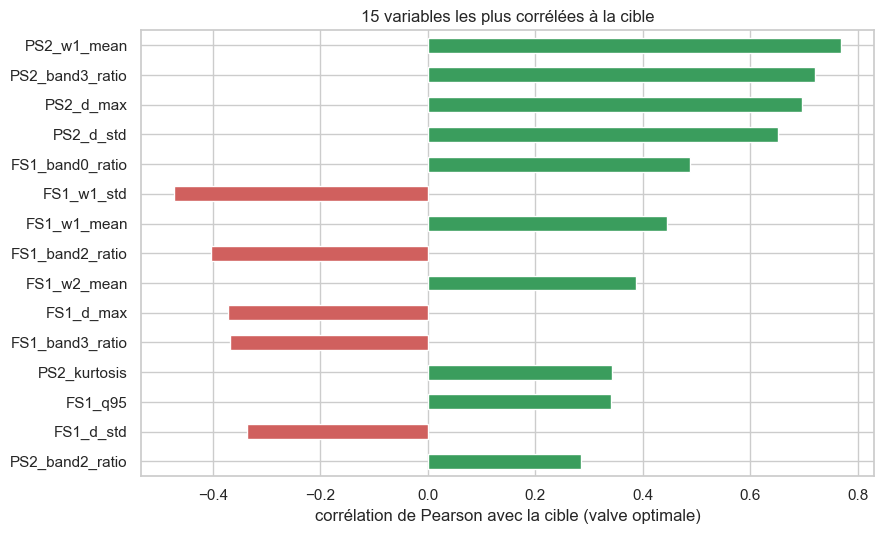

,corr
PS2_w1_mean,0.768
PS2_band3_ratio,0.720
PS2_d_max,0.697
PS2_d_std,0.651
FS1_band0_ratio,0.488
FS1_w1_std,-0.472
FS1_w1_mean,0.445
FS1_band2_ratio,-0.403
FS1_w2_mean,0.387
FS1_d_max,-0.371


In [29]:
corr_target = X_train.apply(lambda c: c.corr(y_train)).sort_values(key=np.abs, ascending=False)
top_corr = corr_target.head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
top_corr.iloc[::-1].plot.barh(ax=ax, color=np.where(top_corr.iloc[::-1] > 0, "#3a9d5d", "#d0605e"))
ax.set_xlabel("corrélation de Pearson avec la cible (valve optimale)")
ax.set_title("15 variables les plus corrélées à la cible")
plt.tight_layout(); savefig("correlation_cible"); plt.show()
top_corr.to_frame("corr").round(3)

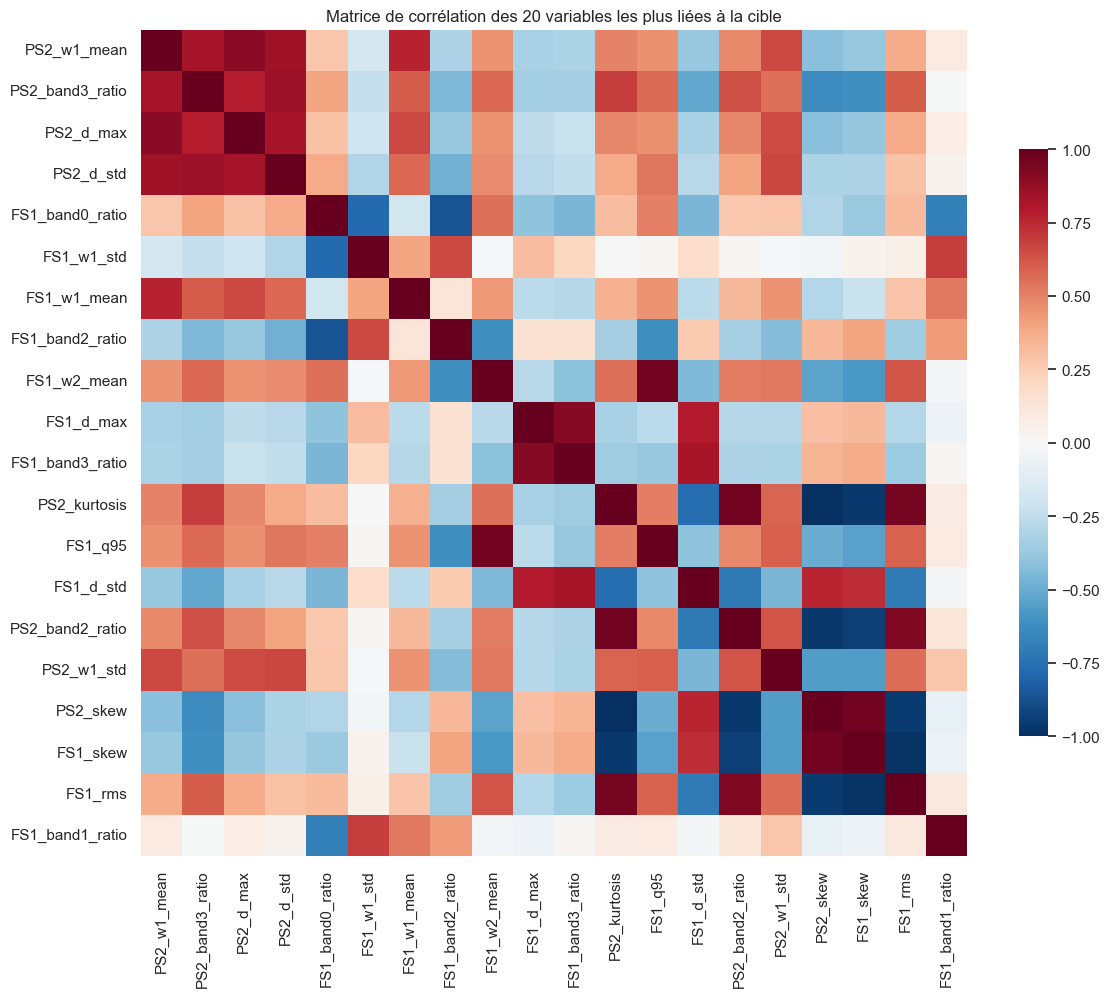

Part des paires de variables avec |r| > 0,95 : 11.3%


In [30]:
top_feats = corr_target.head(20).index
cm = X_train[top_feats].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .7})
plt.title("Matrice de corrélation des 20 variables les plus liées à la cible")
plt.tight_layout(); savefig("matrice_correlation"); plt.show()

with np.errstate(invalid="ignore", divide="ignore"):
    full_corr = np.nan_to_num(X_train.corr().abs().values)
iu = np.triu_indices_from(full_corr, k=1)
frac_high = np.mean(full_corr[iu] > 0.95)
print(f"Part des paires de variables avec |r| > 0,95 : {frac_high:.1%}")
RESULTS["pctHighCorrPairs"] = round(100 * frac_high, 1)

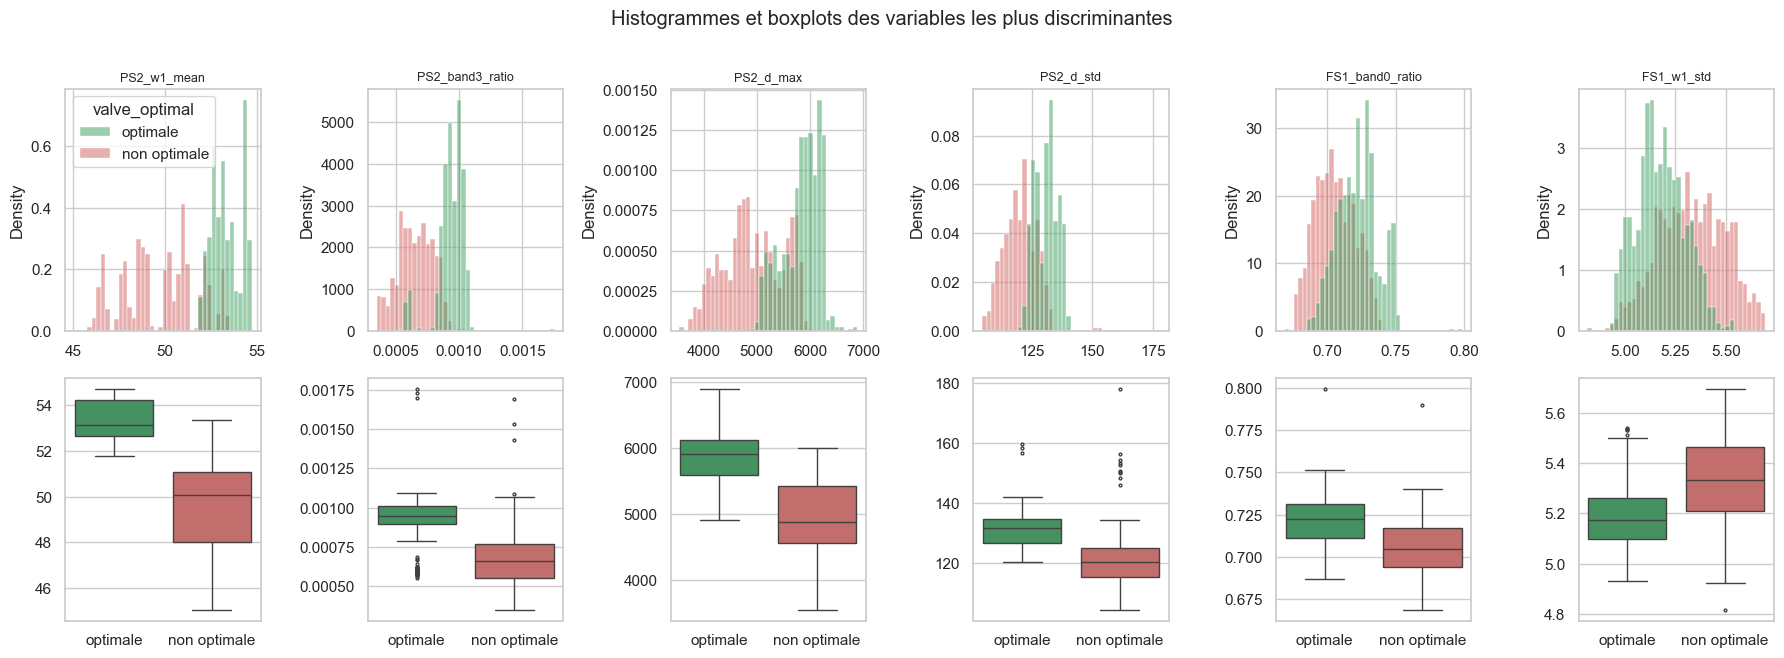

In [31]:
plot_feats = list(corr_target.head(6).index)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
lab = y_train.map({1: "optimale", 0: "non optimale"})
for j, f in enumerate(plot_feats):
    sns.histplot(x=X_train[f], hue=lab, ax=axes[0, j], bins=40, stat="density", common_norm=False,
                 palette={"optimale": "#3a9d5d", "non optimale": "#d0605e"}, legend=(j == 0))
    sns.boxplot(x=lab, y=X_train[f], ax=axes[1, j], hue=lab, palette={"optimale": "#3a9d5d", "non optimale": "#d0605e"}, fliersize=2, legend=False)
    axes[0, j].set_title(f, fontsize=9); axes[0, j].set_xlabel(""); axes[1, j].set_xlabel(""); axes[1, j].set_ylabel("")
plt.suptitle("Histogrammes et boxplots des variables les plus discriminantes", y=1.01)
plt.tight_layout(); savefig("histogrammes_boxplots"); plt.show()

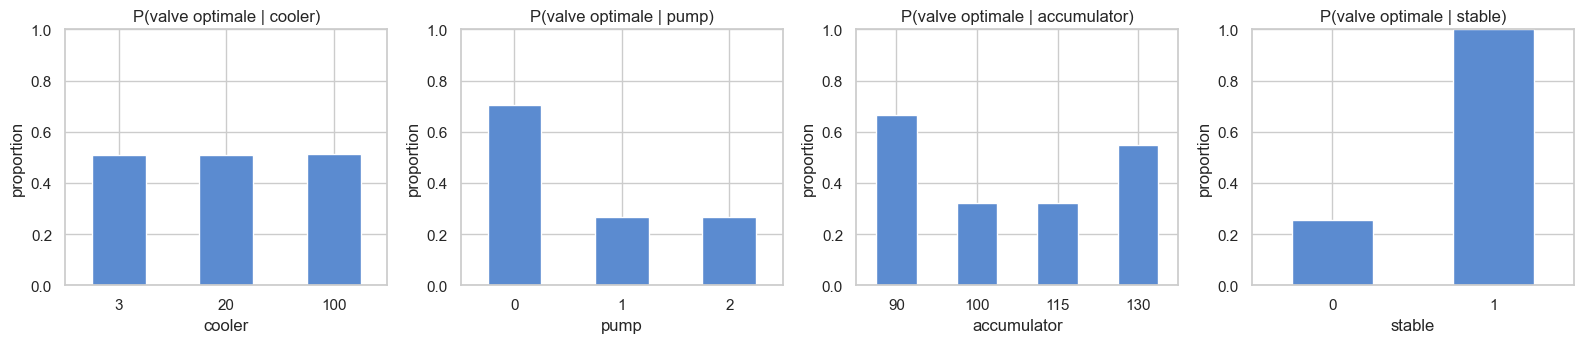

,V de Cramér avec valve
cooler,0.004
pump,0.307
accumulator,0.171
stable,0.708


In [32]:
# Relation entre la valve et les autres conditions (analyse des causes)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(axes, ["cooler", "pump", "accumulator", "stable"]):
    ct = pd.crosstab(profile[col], profile["valve"] == 100, normalize="index")[True]
    ct.plot.bar(ax=ax, color="#5b8bd0"); ax.set_ylim(0, 1); ax.set_title(f"P(valve optimale | {col})")
    ax.set_ylabel("proportion"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("valve_vs_autres_conditions"); plt.show()
cramers = {}
for col in ["cooler", "pump", "accumulator", "stable"]:
    ct = pd.crosstab(profile[col], profile["valve"])
    chi2 = stats.chi2_contingency(ct)[0]
    cramers[col] = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
pd.Series(cramers, name="V de Cramér avec valve").round(3).to_frame()

**Lecture.** L'état du refroidisseur est indépendant de celui de la valve (V ≈ 0). Les
associations avec la pompe, l'accumulateur et surtout l'indicateur de stabilité viennent du
**plan d'expérience** et non d'un lien physique : chaque niveau dégradé de la valve (73, 80,
90 %) est testé exactement 120 fois pour chaque état de la pompe, et tous les cycles « non
stables » (phases de transition après un changement de configuration) ont été enregistrés avec
une valve à 100 %. Ces variables ne sont donc pas des causes de la dégradation de la valve
(et ne sont de toute façon pas disponibles en production) ; la dégradation doit être détectée
dans la **signature des signaux** de pression et de débit.

### 1.9 Sélection de variables

On combine plusieurs familles de méthodes :

1. **Filtre de variance** : suppression des variables (quasi) constantes ;
2. **Filtre de corrélation** : pour chaque paire avec |r| > 0,95, une seule variable est
   conservée (réduction de la redondance, utile pour Naive Bayes et la régression logistique) ;
3. **Méthodes univariées** : test ANOVA F et information mutuelle ;
4. **Méthode embarquée** : régression logistique pénalisée L1 et importance des variables
   d'une forêt aléatoire.

Dans les pipelines de modélisation, le filtre de corrélation et la sélection `SelectKBest`
(ANOVA F) sont placés **à l'intérieur du pipeline** : ils sont réappris dans chaque pli de
validation croisée, ce qui évite toute fuite d'information.

In [33]:
"""Sélection de variables utilisable à l'intérieur d'un Pipeline scikit-learn.

La sélection est apprise sur les plis d'entraînement uniquement, ce qui évite
toute fuite d'information vers les plis de validation ou le jeu de test.
"""

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Supprime une variable de chaque paire dont |corrélation| > threshold.

    Parcourt les colonnes dans l'ordre et garde une colonne seulement si elle
    n'est pas trop corrélée avec une colonne déjà gardée.
    """

    def __init__(self, threshold: float = 0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        Xa = np.asarray(X, dtype=float)
        std = Xa.std(axis=0)
        with np.errstate(invalid="ignore", divide="ignore"):
            corr = np.nan_to_num(np.abs(np.corrcoef(Xa, rowvar=False)))
        keep: list[int] = []
        for j in range(Xa.shape[1]):
            if std[j] == 0:
                continue  # variable constante
            if all(corr[j, k] <= self.threshold for k in keep):
                keep.append(j)
        self.support_ = np.zeros(Xa.shape[1], dtype=bool)
        self.support_[keep] = True
        self.feature_names_in_ = (
            np.asarray(X.columns) if isinstance(X, pd.DataFrame) else None
        )
        self.n_features_in_ = Xa.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self, "support_")
        if isinstance(X, pd.DataFrame):
            return X.loc[:, self.support_]
        return np.asarray(X)[:, self.support_]

    def get_support(self):
        check_is_fitted(self, "support_")
        return self.support_

    def get_feature_names_out(self, input_features=None):
        names = input_features if input_features is not None else self.feature_names_in_
        if names is None:
            names = np.array([f"x{i}" for i in range(self.n_features_in_)])
        return np.asarray(names)[self.support_]

In [34]:
vt = VarianceThreshold(1e-8).fit(X_train)
X_tr_v = X_train.loc[:, vt.get_support()]
cf = CorrelationFilter(0.95).fit(X_tr_v)
X_tr_c = cf.transform(X_tr_v)
print(f"Variables initiales             : {X_train.shape[1]}")
print(f"Après filtre de variance        : {X_tr_v.shape[1]}")
print(f"Après filtre de corrélation 0,95: {X_tr_c.shape[1]}")
RESULTS["nAfterCorr"] = X_tr_c.shape[1]

Xs = StandardScaler().fit_transform(X_tr_c)
F, pval = f_classif(Xs, y_train)
mi = mutual_info_classif(Xs, y_train, random_state=RANDOM_STATE)
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.1, max_iter=5000).fit(Xs, y_train)
rf_sel = RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=RANDOM_STATE).fit(X_tr_c, y_train)
scores = pd.DataFrame({
    "ANOVA F": F, "p-value": pval, "info. mutuelle": mi,
    "|coef L1|": np.abs(l1.coef_[0]), "importance RF": rf_sel.feature_importances_,
}, index=X_tr_c.columns)
ranks = scores.drop(columns="p-value").rank(ascending=False)
scores["rang moyen"] = ranks.mean(axis=1)
scores = scores.sort_values("rang moyen")
print(f"Variables non nulles avec L1 (C=0,1) : {(scores['|coef L1|'] > 0).sum()}")
RESULTS["nL1NonZero"] = int((scores["|coef L1|"] > 0).sum())
scores.head(15).round(4)

Variables initiales             : 90
Après filtre de variance        : 87
Après filtre de corrélation 0,95: 47
Variables non nulles avec L1 (C=0,1) : 13


,ANOVA F,p-value,info. mutuelle,|coef L1|,importance RF,rang moyen
PS2_w1_mean,2874.0712,0.0,0.5219,4.5675,0.1046,2.250
PS2_band3_ratio,2152.7981,0.0,0.4652,2.1440,0.0729,3.250
FS1_w1_std,571.8924,0.0,0.1497,1.2718,0.0247,8.500
FS1_band0_ratio,623.7910,0.0,0.1496,0.4254,0.0135,10.000
PS2_d_max,1885.7225,0.0,0.3782,0.0000,0.0533,11.375
PS2_skew,157.1637,0.0,0.6664,0.0000,0.1716,11.875
PS2_d_std,1467.1875,0.0,0.3628,0.0000,0.0430,12.125
PS2_argmax_s,85.0585,0.0,0.6443,0.0000,0.2079,12.625
FS1_std,70.6805,0.0,0.1802,0.2772,0.0114,14.000
FS1_argmax_s,62.3635,0.0,0.4432,0.0000,0.1304,14.875


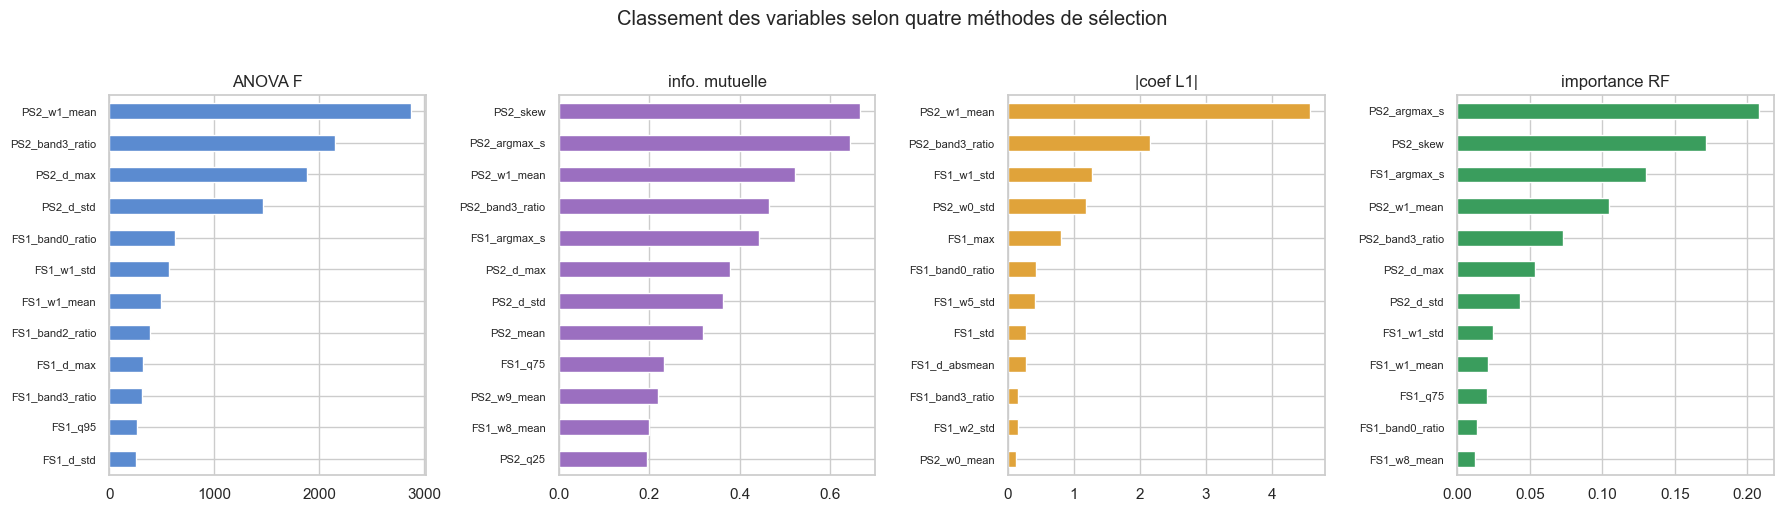

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col, c in zip(axes, ["ANOVA F", "info. mutuelle", "|coef L1|", "importance RF"],
                      ["#5b8bd0", "#9b6fc0", "#e0a33a", "#3a9d5d"]):
    s = scores[col].sort_values(ascending=False).head(12).iloc[::-1]
    s.plot.barh(ax=ax, color=c); ax.set_title(col); ax.tick_params(axis="y", labelsize=8)
plt.suptitle("Classement des variables selon quatre méthodes de sélection", y=1.02)
plt.tight_layout(); savefig("selection_variables"); plt.show()

**Choix du nombre de variables `k`.** On mesure en validation croisée l'AUC d'une régression
logistique et d'une forêt aléatoire en fonction du nombre de variables retenues par ANOVA F.

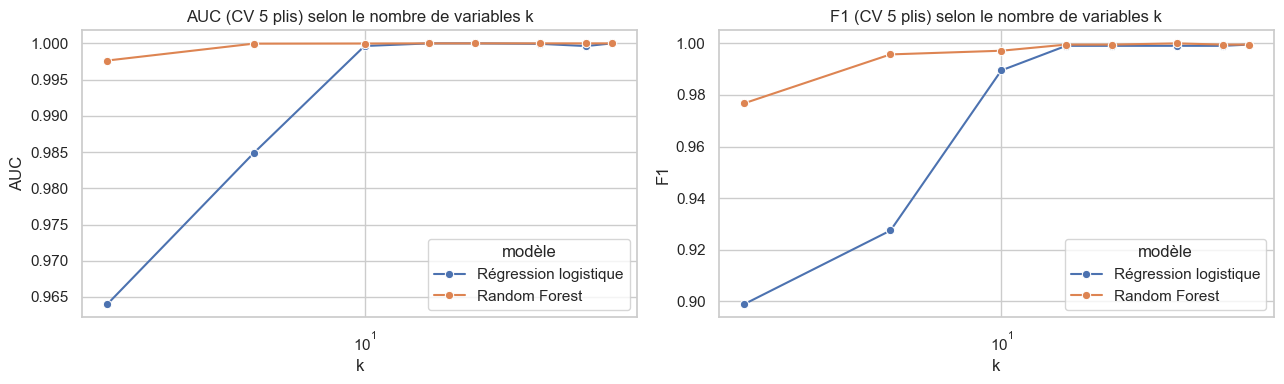

AUC                                  F1                      
modèle Random Forest Régression logistique Random Forest Régression logistique
k                                                                             
2             0.9976                0.9640        0.9768                0.8989
5             1.0000                0.9849        0.9957                0.9275
10            1.0000                0.9996        0.9971                0.9895
15            1.0000                1.0000        0.9995                0.9991
20            1.0000                1.0000        0.9995                0.9991
30            1.0000                0.9999        1.0000                0.9991
40            1.0000                0.9996        0.9995                0.9990
47            1.0000                1.0000        0.9995                0.9995

In [36]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
n_max = X_tr_c.shape[1]
k_grid = sorted({k for k in [2, 5, 10, 15, 20, 30, 40, 60, n_max] if k <= n_max})

def sel_pipe(clf, k):
    return Pipeline([("corr", CorrelationFilter(0.95)), ("scaler", StandardScaler()),
                     ("select", SelectKBest(f_classif, k=k)), ("clf", clf)])

curve = []
for k in k_grid:
    for name, clf in [("Régression logistique", LogisticRegression(max_iter=5000)),
                      ("Random Forest", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))]:
        s = cross_validate(sel_pipe(clf, k), X_train, y_train, cv=CV, scoring=["roc_auc", "f1"])
        curve.append({"k": k, "modèle": name, "AUC": s["test_roc_auc"].mean(), "F1": s["test_f1"].mean()})
curve = pd.DataFrame(curve)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["AUC", "F1"]):
    sns.lineplot(data=curve, x="k", y=m, hue="modèle", marker="o", ax=ax)
    ax.set_xscale("log"); ax.set_title(f"{m} (CV 5 plis) selon le nombre de variables k")
plt.tight_layout(); savefig("choix_k"); plt.show()
curve.pivot(index="k", columns="modèle", values=["AUC", "F1"]).round(4)

In [37]:
# k par défaut : plus petit k dont l'AUC moyenne (2 modèles) est à moins de 0,005 du maximum
mean_auc = curve.groupby("k")["AUC"].mean()
K_DEFAULT = int(mean_auc[mean_auc >= mean_auc.max() - 0.005].index.min())
print("k retenu par défaut :", K_DEFAULT, "(k sera de nouveau optimisé à l'étape 4)")
RESULTS["kDefault"] = K_DEFAULT

k retenu par défaut : 10 (k sera de nouveau optimisé à l'étape 4)


## 2. Modélisation

| Modèle | Nature | Frontière de décision | Hypothèses / adaptation aux données |
|---|---|---|---|
| Régression logistique | paramétrique, linéaire | hyperplan | rapide, interprétable, sensible à la colinéarité (d'où le filtre de corrélation) ; référence linéaire |
| k-NN | non paramétrique, à base d'instances | non linéaire, locale | nécessite des variables standardisées ; souffre du bruit et de la grande dimension |
| Arbre de décision | non paramétrique | non linéaire, par morceaux | insensible aux échelles et aux valeurs extrêmes, interprétable ; forte variance |
| Naive Bayes gaussien | probabiliste génératif | quadratique | suppose des variables indépendantes et gaussiennes : hypothèse violée ici (variables corrélées), sert de référence simple |
| SVM (noyau RBF) | à marge maximale | non linéaire (noyau) | performant en dimension moyenne, robuste au bruit grâce à la marge ; sensible à C et γ |
| Random Forest | ensemble (bagging) | non linéaire | réduit la variance des arbres, robuste au bruit et aux valeurs extrêmes |
| Gradient Boosting / AdaBoost | ensemble (boosting) | non linéaire | réduit le biais en corrigeant séquentiellement les erreurs ; risque de sur-apprentissage si mal régularisé |
| Stacking (LR + SVM + RF) | ensemble hétérogène | combinaison | combine des modèles de biais différents via un méta-modèle logistique |

Tous les modèles partagent le même pipeline :
`CorrelationFilter(0,95) → StandardScaler → SelectKBest(ANOVA F, k) → classifieur`.

In [38]:
def make_pipeline(clf, k=None):
    return sel_pipe(clf, K_DEFAULT if k is None else k)

base_models = {
    "Régression logistique": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "k-NN": KNeighborsClassifier(n_neighbors=5),
    "Arbre de décision": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
    "Stacking (LR+SVM+RF)": StackingClassifier(
        estimators=[("lr", LogisticRegression(max_iter=5000)),
                    ("svm", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
                    ("rf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE))],
        final_estimator=LogisticRegression(max_iter=5000), cv=5, n_jobs=-1),
}
pipelines = {name: make_pipeline(clf) for name, clf in base_models.items()}

## 3. Évaluation des modèles

### 3.1 Validation croisée stratifiée (5 plis) sur les 2000 cycles d'entraînement

Pour chaque modèle on mesure accuracy, précision, rappel, F1 et AUC sur les plis de
validation, ainsi que les scores sur les plis d'entraînement : l'écart entre les deux
renseigne sur la **variance** (sur-apprentissage), le niveau du score de validation sur le
**biais**.

In [39]:
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def cv_table(pipes, cv=CV):
    rows = []
    for name, pipe in pipes.items():
        t0 = time.time()
        s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
        row = {"modèle": name}
        for m in SCORING:
            row[m] = s[f"test_{m}"].mean(); row[f"{m}_std"] = s[f"test_{m}"].std()
        row["F1 train"] = s["train_f1"].mean()
        row["écart train-val (F1)"] = row["F1 train"] - row["f1"]
        row["temps (s)"] = time.time() - t0
        rows.append(row)
    return pd.DataFrame(rows).set_index("modèle")

res_base = cv_table(pipelines).sort_values("roc_auc", ascending=False)
res_base[["accuracy", "precision", "recall", "f1", "roc_auc", "roc_auc_std", "F1 train", "écart train-val (F1)", "temps (s)"]].round(4)

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,F1 train,écart train-val (F1),temps (s)
modèle,,,,,,,,,
Random Forest,0.9970,0.9972,0.9971,0.9971,1.0000,0.0000,1.0000,0.0029,0.9520
Stacking (LR+SVM+RF),0.9945,0.9934,0.9962,0.9948,0.9999,0.0001,0.9969,0.0021,3.2909
SVM (RBF),0.9945,0.9943,0.9953,0.9948,0.9999,0.0001,0.9962,0.0014,0.9981
Gradient Boosting,0.9965,0.9962,0.9971,0.9967,0.9998,0.0003,1.0000,0.0033,0.5568
Régression logistique,0.9890,0.9905,0.9886,0.9895,0.9996,0.0003,0.9906,0.0011,1.6555
k-NN,0.9935,0.9953,0.9924,0.9938,0.9994,0.0011,0.9970,0.0032,0.9095
AdaBoost,0.9910,0.9915,0.9914,0.9914,0.9992,0.0014,0.9995,0.0081,0.2392
Arbre de décision,0.9865,0.9878,0.9867,0.9872,0.9865,0.0038,1.0000,0.0128,0.0858
Naive Bayes,0.9010,0.8989,0.9163,0.9069,0.9757,0.0048,0.9070,0.0002,0.8554


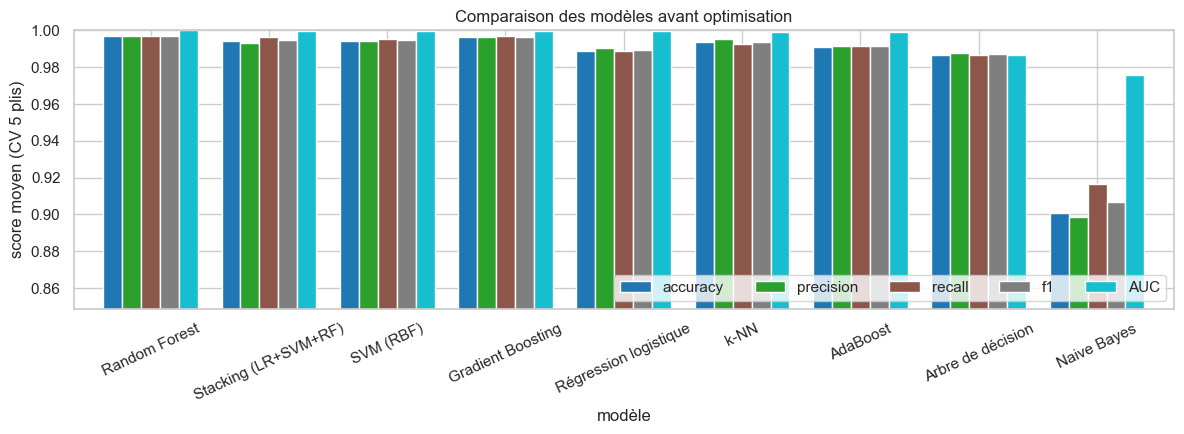

In [40]:
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_df = res_base[["accuracy", "precision", "recall", "f1", "roc_auc"]].rename(columns={"roc_auc": "AUC"})
plot_df.plot.bar(ax=ax, width=0.8, colormap="tab10")
lo = max(0.0, plot_df.values.min() - 0.05)
ax.set_ylim(lo, 1.0); ax.set_ylabel("score moyen (CV 5 plis)"); ax.tick_params(axis="x", rotation=25)
ax.legend(ncol=5, loc="lower right"); ax.set_title("Comparaison des modèles avant optimisation")
plt.tight_layout(); savefig("comparaison_modeles_base"); plt.show()

### 3.2 Matrices de confusion et courbes ROC (prédictions hors-pli)

Les prédictions sont obtenues par `cross_val_predict` : chaque cycle d'entraînement est
prédit par un modèle qui ne l'a pas vu.

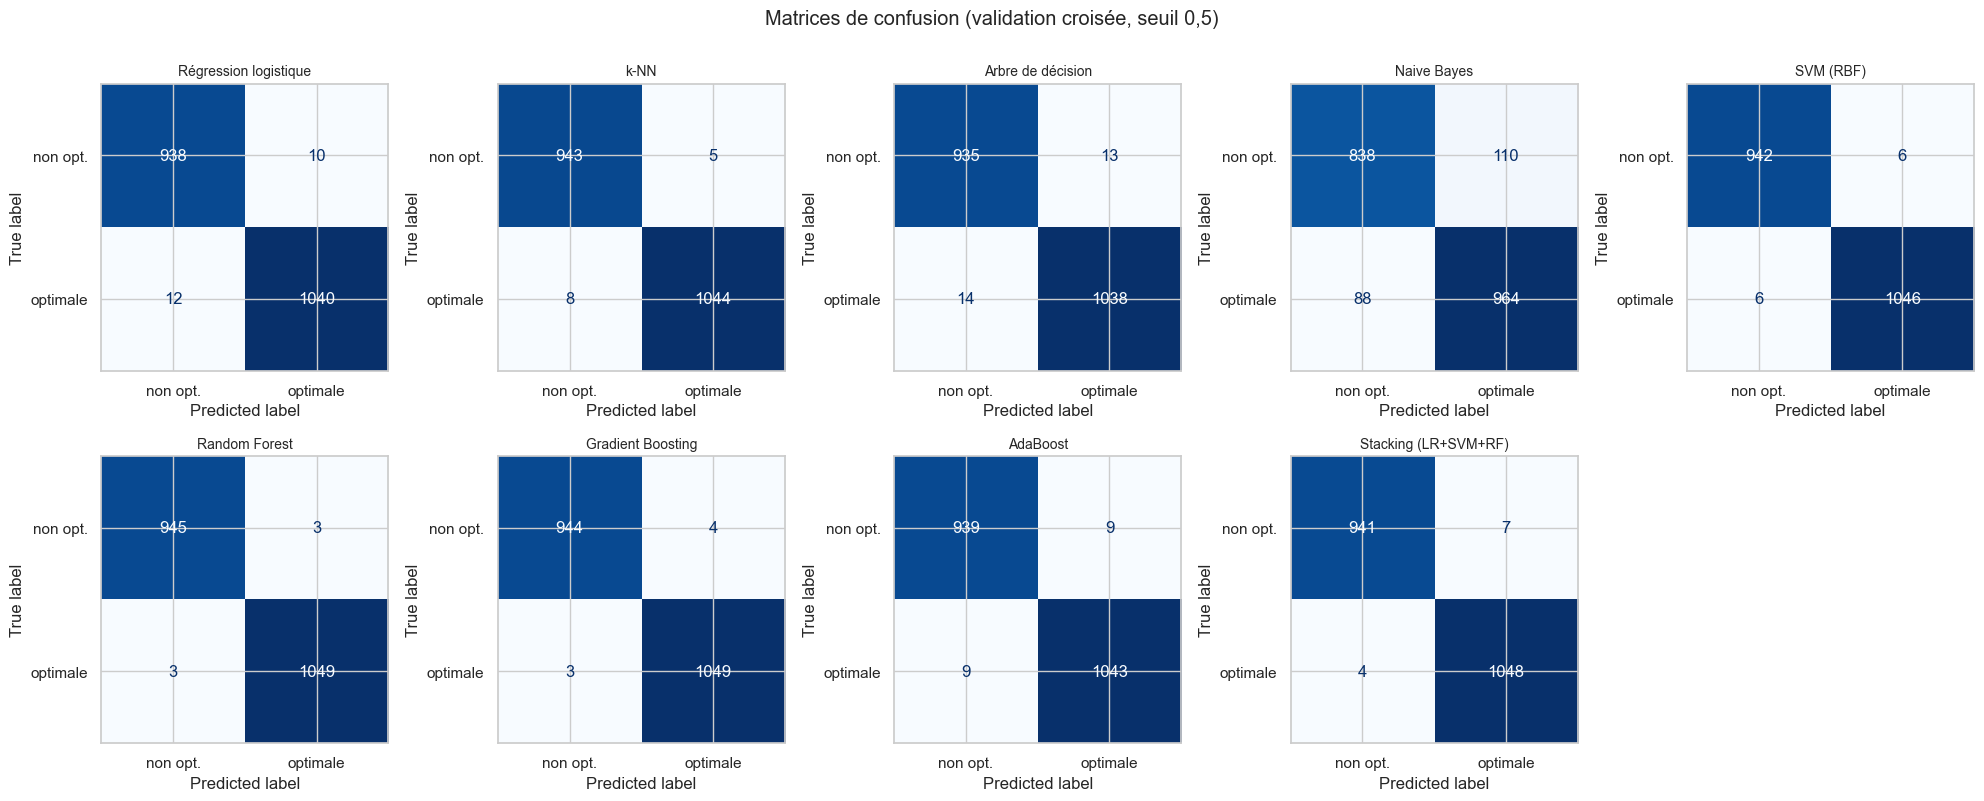

In [41]:
oof_proba = {}
for name, pipe in pipelines.items():
    oof_proba[name] = cross_val_predict(pipe, X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]

names = list(pipelines)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, name in zip(axes.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(y_train, (oof_proba[name] >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=["non opt.", "optimale"], cmap="Blues")
    ax.set_title(name, fontsize=10)
axes.ravel()[-1].axis("off")
plt.suptitle("Matrices de confusion (validation croisée, seuil 0,5)", y=1.0)
plt.tight_layout(); savefig("matrices_confusion_cv"); plt.show()

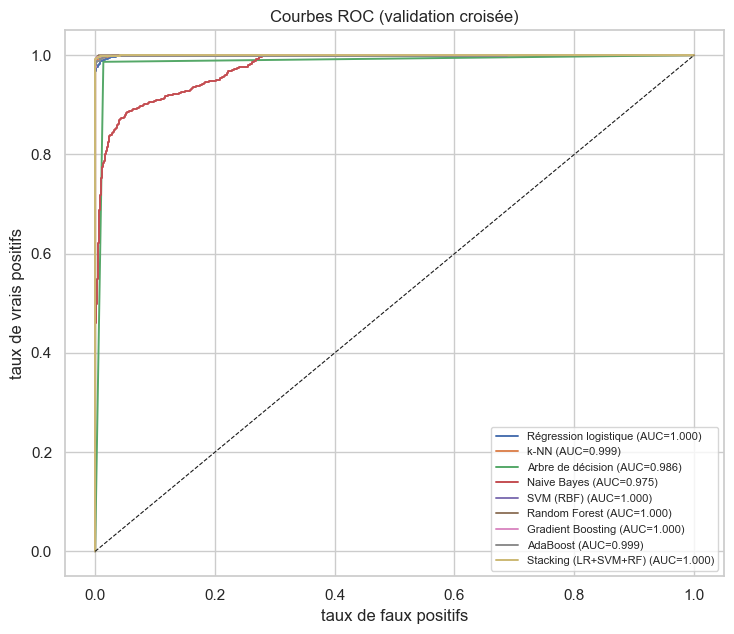

In [42]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name in names:
    fpr, tpr, _ = roc_curve(y_train, oof_proba[name])
    ax.plot(fpr, tpr, lw=1.4, label=f"{name} (AUC={roc_auc_score(y_train, oof_proba[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("taux de faux positifs"); ax.set_ylabel("taux de vrais positifs")
ax.set_title("Courbes ROC (validation croisée)"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); savefig("roc_cv"); plt.show()

### 3.3 Compromis biais / variance : courbes d'apprentissage

Une courbe d'entraînement très haute avec un écart important à la courbe de validation
traduit une **variance** élevée ; deux courbes basses et proches traduisent un **biais**
élevé.

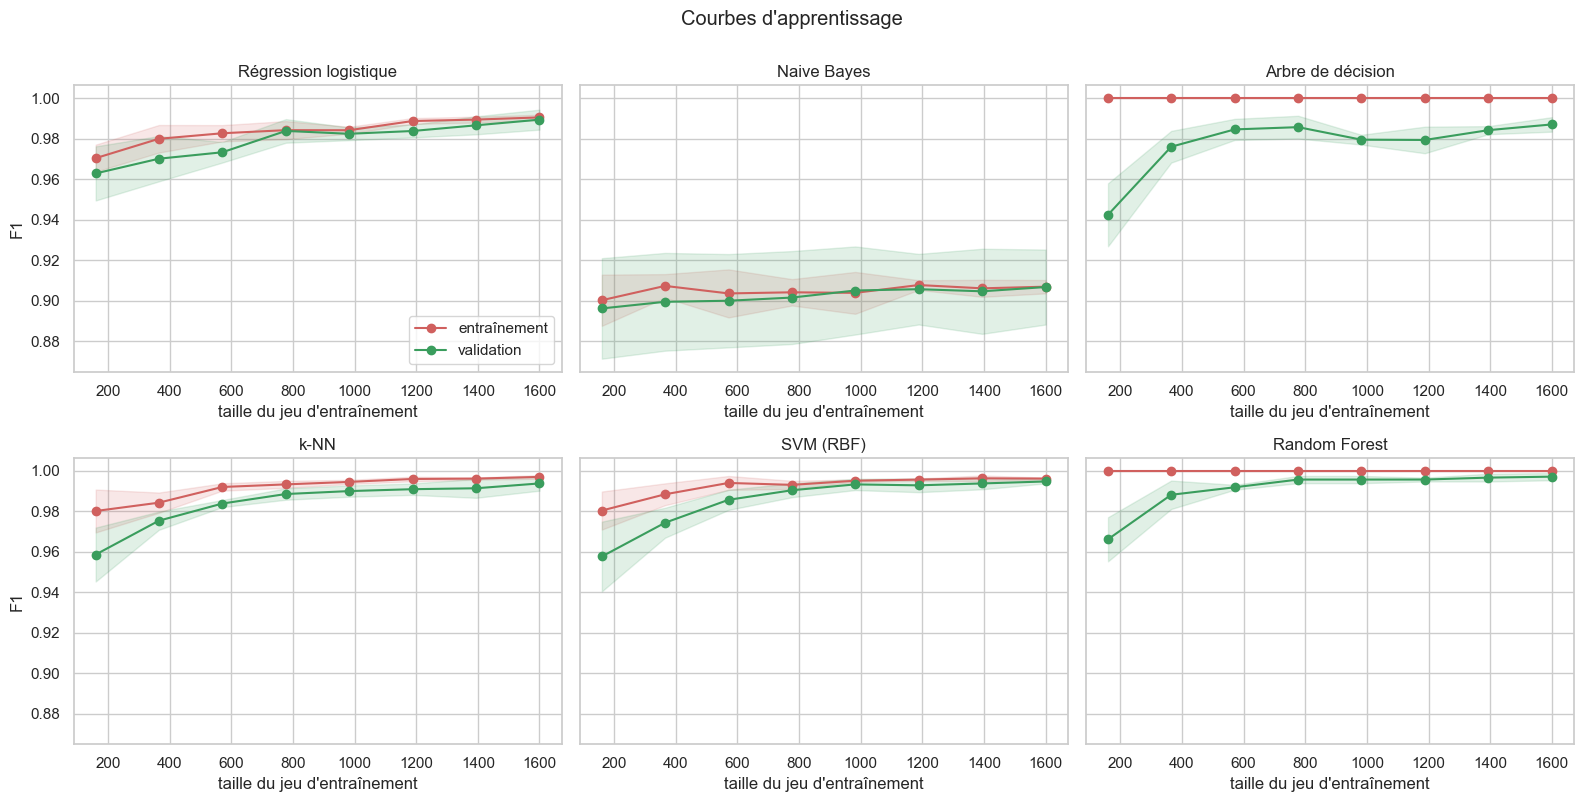

In [43]:
lc_models = ["Régression logistique", "Naive Bayes", "Arbre de décision", "k-NN", "SVM (RBF)", "Random Forest"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, name in zip(axes.ravel(), lc_models):
    sizes, tr, va = learning_curve(pipelines[name], X_train, y_train, cv=CV, scoring="f1",
                                   train_sizes=np.linspace(0.1, 1.0, 8), shuffle=True,
                                   random_state=RANDOM_STATE, n_jobs=-1)
    ax.plot(sizes, tr.mean(1), "o-", color="#d0605e", label="entraînement")
    ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), color="#d0605e", alpha=.15)
    ax.plot(sizes, va.mean(1), "o-", color="#3a9d5d", label="validation")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color="#3a9d5d", alpha=.15)
    ax.set_title(name); ax.set_xlabel("taille du jeu d'entraînement")
axes[0, 0].set_ylabel("F1"); axes[1, 0].set_ylabel("F1"); axes[0, 0].legend(loc="lower right")
plt.suptitle("Courbes d'apprentissage", y=1.0)
plt.tight_layout(); savefig("courbes_apprentissage"); plt.show()

### 3.4 Robustesse de la validation : plis contigus vs plis mélangés

Les cycles successifs se ressemblent (mêmes conditions maintenues pendant plusieurs
cycles). Une validation croisée à plis **mélangés** peut donc être optimiste. On la compare
à une validation à **plis contigus** (`KFold` sans mélange), plus proche de la situation du
test final (cycles futurs).

In [44]:
CV_BLOCK = KFold(n_splits=5, shuffle=False)
rob = []
for name in ["Régression logistique", "SVM (RBF)", "Random Forest", "Gradient Boosting"]:
    a = cross_validate(pipelines[name], X_train, y_train, cv=CV, scoring=["f1", "roc_auc"], n_jobs=-1)
    b = cross_validate(pipelines[name], X_train, y_train, cv=CV_BLOCK, scoring=["f1", "roc_auc"], n_jobs=-1)
    rob.append({"modèle": name, "F1 plis mélangés": a["test_f1"].mean(), "F1 plis contigus": b["test_f1"].mean(),
                "AUC plis mélangés": a["test_roc_auc"].mean(), "AUC plis contigus": b["test_roc_auc"].mean()})
rob = pd.DataFrame(rob).set_index("modèle"); rob.round(4)

,F1 plis mélangés,F1 plis contigus,AUC plis mélangés,AUC plis contigus
modèle,,,,
Régression logistique,0.9895,0.9791,0.9996,0.9994
SVM (RBF),0.9948,0.9780,0.9999,0.9993
Random Forest,0.9971,0.9353,1.0000,0.9939
Gradient Boosting,0.9967,0.9249,0.9998,0.9858


## 4. Optimisation des hyperparamètres

* **Grid Search** (recherche exhaustive) pour les modèles qui ont peu d'hyperparamètres :
  régression logistique, k-NN, arbre de décision, SVM, Naive Bayes ;
* **Random Search** (tirage aléatoire de 40 combinaisons) pour les ensembles dont l'espace
  est plus grand : Random Forest et Gradient Boosting.

Le nombre de variables `k` de `SelectKBest` est optimisé **en même temps** que les
hyperparamètres du classifieur. Le critère est l'AUC en validation croisée stratifiée à 5
plis ; chaque recherche est de plus réévaluée en F1.

In [45]:
k_opts = sorted({k for k in [5, 10, 20, 30, 40, n_max] if k <= n_max})
searches = {
    "Régression logistique": ("grid", {"select__k": k_opts, "clf__C": [0.01, 0.1, 1, 10, 100],
                                       "clf__penalty": ["l1", "l2"], "clf__solver": ["liblinear"]}),
    "k-NN": ("grid", {"select__k": k_opts, "clf__n_neighbors": [3, 5, 7, 11, 15, 21, 31],
                      "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}),
    "Arbre de décision": ("grid", {"select__k": k_opts, "clf__max_depth": [3, 5, 8, 12, None],
                                   "clf__min_samples_leaf": [1, 5, 10, 20], "clf__criterion": ["gini", "entropy"]}),
    "Naive Bayes": ("grid", {"select__k": k_opts, "clf__var_smoothing": np.logspace(-11, -3, 9)}),
    "SVM (RBF)": ("grid", {"select__k": k_opts, "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.001, 0.01, 0.1]}),
    "Random Forest": ("random", {"select__k": k_opts, "clf__n_estimators": randint(100, 600),
                                 "clf__max_depth": [None, 5, 10, 20], "clf__min_samples_leaf": randint(1, 10),
                                 "clf__max_features": ["sqrt", "log2", 0.3, 0.5]}),
    "Gradient Boosting": ("random", {"select__k": k_opts, "clf__n_estimators": randint(100, 500),
                                     "clf__learning_rate": loguniform(0.01, 0.3), "clf__max_depth": randint(2, 6),
                                     "clf__subsample": uniform(0.6, 0.4)}),
}

best = {}; tuning_rows = []
for name, (kind, space) in searches.items():
    t0 = time.time()
    if kind == "grid":
        search = GridSearchCV(pipelines[name], space, cv=CV, scoring="roc_auc", n_jobs=-1, refit=True)
    else:
        search = RandomizedSearchCV(pipelines[name], space, n_iter=40, cv=CV, scoring="roc_auc",
                                    n_jobs=-1, refit=True, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    best[name] = search.best_estimator_
    n_cand = len(search.cv_results_["params"])
    tuning_rows.append({"modèle": name, "méthode": "Grid" if kind == "grid" else "Random",
                        "combinaisons": n_cand, "AUC avant": res_base.loc[name, "roc_auc"],
                        "AUC après": search.best_score_, "temps (s)": time.time() - t0,
                        "meilleurs paramètres": {k.replace("clf__", "").replace("select__", ""): (float(f"{v:.4g}") if isinstance(v, float) else v)
                                                 for k, v in search.best_params_.items()}})
    print(f"{name:22s} {kind:6s} AUC={search.best_score_:.4f}  ({time.time()-t0:.0f} s)  {search.best_params_}")
tuning = pd.DataFrame(tuning_rows).set_index("modèle")
tuning[["méthode", "combinaisons", "AUC avant", "AUC après", "temps (s)"]].round(4)

Régression logistique  grid   AUC=1.0000  (1 s)  {'clf__C': 0.1, 'clf__penalty': 'l1', 'clf__solver': 'liblinear', 'select__k': 20}
k-NN                   grid   AUC=1.0000  (2 s)  {'clf__n_neighbors': 7, 'clf__p': 2, 'clf__weights': 'distance', 'select__k': 5}
Arbre de décision      grid   AUC=0.9990  (3 s)  {'clf__criterion': 'gini', 'clf__max_depth': 3, 'clf__min_samples_leaf': 5, 'select__k': 20}
Naive Bayes            grid   AUC=0.9757  (1 s)  {'clf__var_smoothing': np.float64(0.001), 'select__k': 10}
SVM (RBF)              grid   AUC=1.0000  (9 s)  {'clf__C': 10, 'clf__gamma': 0.001, 'select__k': 40}
Random Forest          random AUC=1.0000  (29 s)  {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 3, 'clf__n_estimators': 314, 'select__k': 20}
Gradient Boosting      random AUC=1.0000  (68 s)  {'clf__learning_rate': np.float64(0.07357031542417702), 'clf__max_depth': 2, 'clf__n_estimators': 351, 'clf__subsample': np.float64(0.8428136990746738), 'select__k

,méthode,combinaisons,AUC avant,AUC après,temps (s)
modèle,,,,,
Régression logistique,Grid,60,0.9996,1.0000,0.7349
k-NN,Grid,168,0.9994,1.0000,1.9905
Arbre de décision,Grid,240,0.9865,0.9990,3.2871
Naive Bayes,Grid,54,0.9757,0.9757,0.5456
SVM (RBF),Grid,96,0.9999,1.0000,8.8337
Random Forest,Random,40,1.0000,1.0000,28.5245
Gradient Boosting,Random,40,0.9998,1.0000,68.0891


In [46]:
# Ensemble final : stacking des trois meilleurs modèles optimisés
top3 = tuning.sort_values("AUC après", ascending=False).index[:3].tolist()
print("Modèles empilés :", top3)
stack_opt = StackingClassifier(estimators=[(f"m{i}", clone(best[n])) for i, n in enumerate(top3)],
                               final_estimator=LogisticRegression(max_iter=5000), cv=5, n_jobs=-1)
best["Stacking optimisé"] = stack_opt
res_opt = cv_table(best).sort_values("roc_auc", ascending=False)
res_opt[["accuracy", "precision", "recall", "f1", "roc_auc", "roc_auc_std", "F1 train", "écart train-val (F1)"]].round(4)

Modèles empilés : ['Régression logistique', 'SVM (RBF)', 'Random Forest']


,accuracy,precision,recall,f1,roc_auc,roc_auc_std,F1 train,écart train-val (F1)
modèle,,,,,,,,
Régression logistique,0.9935,0.9879,1.0000,0.9939,1.0000,0.0000,0.9944,0.0006
SVM (RBF),0.9965,0.9934,1.0000,0.9967,1.0000,0.0000,0.9969,0.0002
Random Forest,0.9995,1.0000,0.9991,0.9995,1.0000,0.0000,1.0000,0.0005
Stacking optimisé,0.9995,0.9991,1.0000,0.9995,1.0000,0.0000,1.0000,0.0005
Gradient Boosting,0.9970,0.9981,0.9962,0.9971,1.0000,0.0000,1.0000,0.0029
k-NN,0.9950,1.0000,0.9905,0.9952,1.0000,0.0000,1.0000,0.0048
Arbre de décision,0.9970,0.9972,0.9972,0.9971,0.9990,0.0012,0.9989,0.0018
Naive Bayes,0.9015,0.8990,0.9173,0.9074,0.9757,0.0049,0.9070,-0.0004


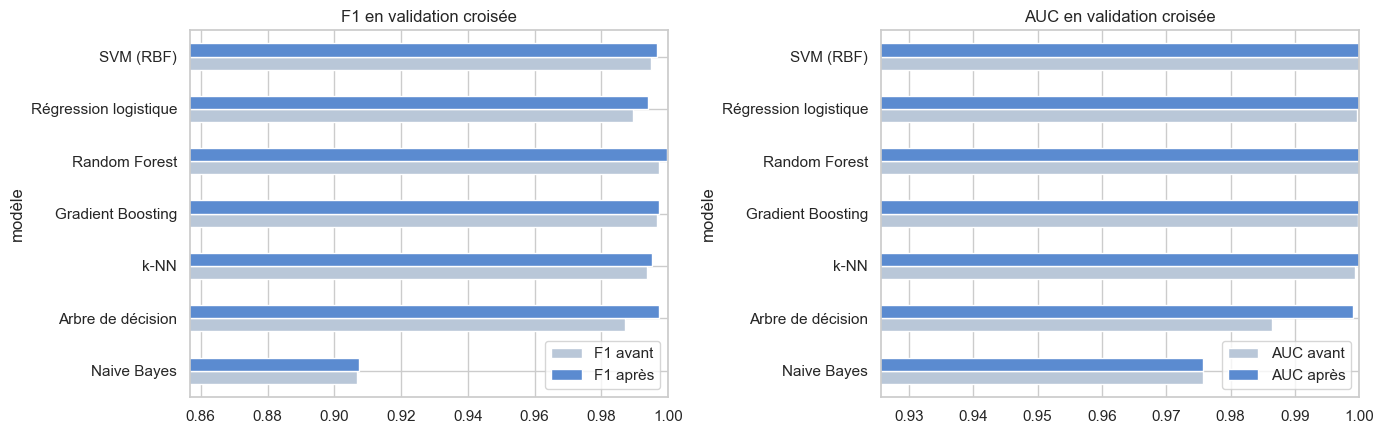

In [47]:
cmp = pd.DataFrame({"F1 avant": res_base["f1"], "F1 après": res_opt["f1"],
                    "AUC avant": res_base["roc_auc"], "AUC après": res_opt["roc_auc"]}).dropna().sort_values("AUC après")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m in zip(axes, ["F1", "AUC"]):
    cmp[[f"{m} avant", f"{m} après"]].plot.barh(ax=ax, color=["#b9c7d8", "#5b8bd0"])
    ax.set_xlim(max(0, cmp[[f"{m} avant", f"{m} après"]].values.min() - 0.05), 1.0); ax.set_title(f"{m} en validation croisée")
plt.tight_layout(); savefig("avant_apres_optimisation"); plt.show()

### 4.1 Choix du modèle final

On retient le modèle ayant la meilleure AUC en validation croisée ; en cas d'égalité
(écart < 0,002), on préfère le modèle le plus simple et celui dont l'écart
entraînement/validation est le plus faible (meilleur compromis biais/variance).

In [48]:
complexity = {"Régression logistique": 1, "Naive Bayes": 1, "k-NN": 2, "Arbre de décision": 2, "SVM (RBF)": 3,
              "Random Forest": 4, "Gradient Boosting": 4, "Stacking optimisé": 5}
cand = res_opt.copy(); cand["complexité"] = cand.index.map(complexity)
near = cand[cand["roc_auc"] >= cand["roc_auc"].max() - 0.002].sort_values(["complexité", "écart train-val (F1)"])
FINAL_NAME = near.index[0]
final_model = best[FINAL_NAME]
print("Modèle final :", FINAL_NAME)
if FINAL_NAME in tuning.index:
    print("Hyperparamètres :", tuning.loc[FINAL_NAME, "meilleurs paramètres"])
RESULTS["finalModel"] = FINAL_NAME
RESULTS["finalCvAuc"] = res_opt.loc[FINAL_NAME, "roc_auc"]; RESULTS["finalCvFone"] = res_opt.loc[FINAL_NAME, "f1"]
RESULTS["finalCvAcc"] = res_opt.loc[FINAL_NAME, "accuracy"]

Modèle final : Régression logistique
Hyperparamètres : {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear', 'k': 20}


## 5. Évaluation finale sur l'échantillon de test (cycles 2001 à 2205)

Le modèle final est réentraîné sur les 2000 cycles d'entraînement puis évalué **une seule
fois** sur les 205 cycles de test. Pour comparaison, tous les modèles optimisés sont aussi
évalués (ce tableau ne sert pas à choisir le modèle, le choix ayant été fait en 4.1).

In [49]:
test_rows, test_proba = [], {}
for name, model in best.items():
    m = clone(model).fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int)
    test_proba[name] = p
    if name == FINAL_NAME:
        final_fitted = m
    test_rows.append({"modèle": name, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
                      "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, p)})
res_test = pd.DataFrame(test_rows).set_index("modèle").sort_values("roc_auc", ascending=False)
res_test.round(4)

,accuracy,precision,recall,f1,roc_auc
modèle,,,,,
Régression logistique,0.8585,0.7157,1.0,0.8343,1.0000
Arbre de décision,1.0000,1.0000,1.0,1.0000,1.0000
SVM (RBF),1.0000,1.0000,1.0,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0,1.0000,1.0000
Gradient Boosting,1.0000,1.0000,1.0,1.0000,1.0000
Stacking optimisé,0.9024,0.7849,1.0,0.8795,1.0000
k-NN,0.9463,0.8690,1.0,0.9299,0.9962
Naive Bayes,0.6585,0.5105,1.0,0.6759,0.9093


Modèle final : Régression logistique

              precision    recall  f1-score   support

non optimale     1.0000    0.7803    0.8766       132
    optimale     0.7157    1.0000    0.8343        73

    accuracy                         0.8585       205
   macro avg     0.8578    0.8902    0.8554       205
weighted avg     0.8988    0.8585    0.8615       205



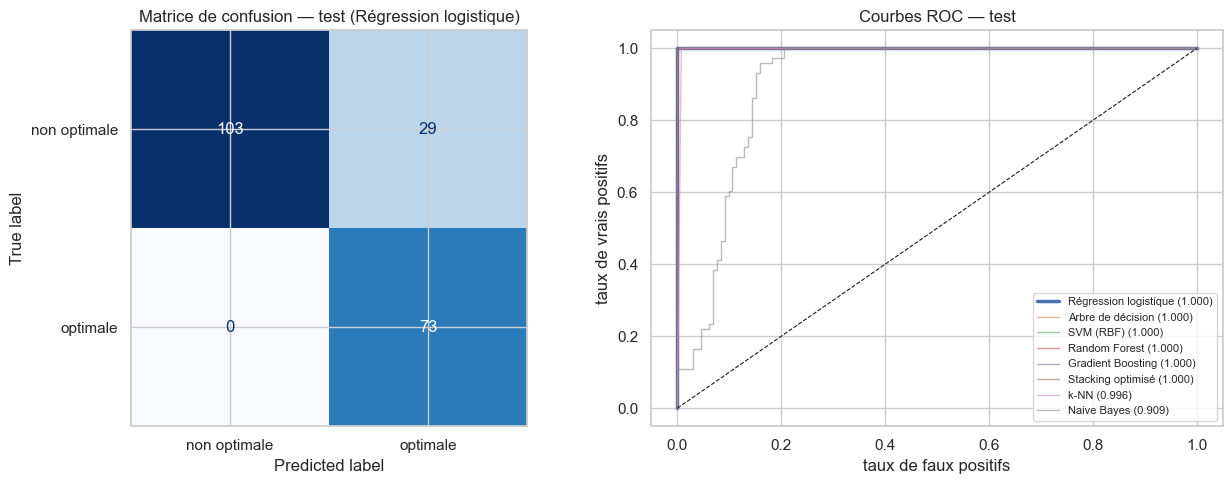

In [50]:
pred_final = final_fitted.predict(X_test)
print(f"Modèle final : {FINAL_NAME}\n")
print(classification_report(y_test, pred_final, target_names=["non optimale", "optimale"], digits=4))
for k, v in res_test.loc[FINAL_NAME].items():
    RESULTS[f"test{k.replace('_', '').replace('f1', 'fone').capitalize()}"] = v

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, ax=axes[0], display_labels=["non optimale", "optimale"], cmap="Blues", colorbar=False)
axes[0].set_title(f"Matrice de confusion — test ({FINAL_NAME})")
for name in res_test.index:
    lw, a = (2.5, 1) if name == FINAL_NAME else (1, .6)
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    axes[1].plot(fpr, tpr, lw=lw, alpha=a, label=f"{name} ({res_test.loc[name, 'roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=.8); axes[1].legend(fontsize=8, loc="lower right")
axes[1].set_xlabel("taux de faux positifs"); axes[1].set_ylabel("taux de vrais positifs"); axes[1].set_title("Courbes ROC — test")
plt.tight_layout(); savefig("test_final"); plt.show()
cmat = confusion_matrix(y_test, pred_final); RESULTS.update(testTN=cmat[0, 0], testFP=cmat[0, 1], testFN=cmat[1, 0], testTP=cmat[1, 1])

### 5.1 Analyse des erreurs

,cycles,erreurs,taux_erreur
valve,,,
73,40,0,0.00
80,42,0,0.00
90,50,29,0.58
100,73,0,0.00


,cycles,erreurs,taux_erreur
stable,,,
0,191,29,0.152
1,14,0,0.000


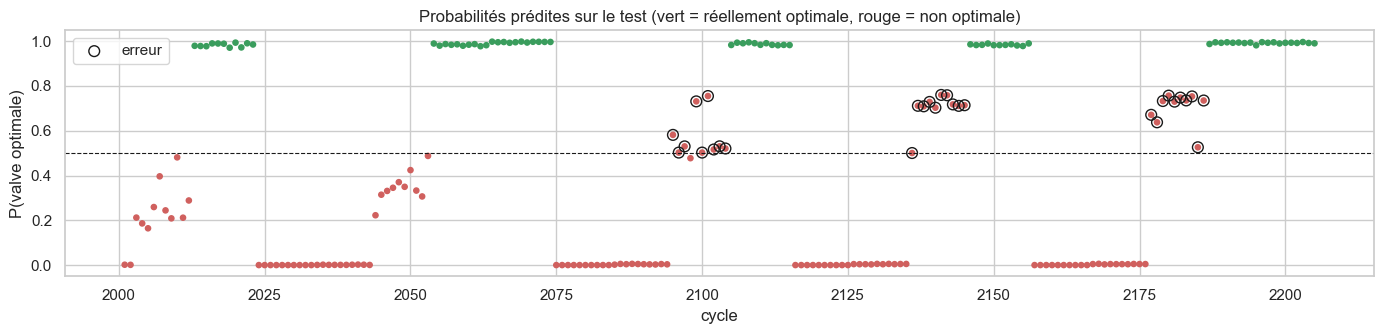

In [51]:
err = profile.iloc[N_TRAIN:].copy()
err["proba_optimale"] = final_fitted.predict_proba(X_test)[:, 1]
err["prédiction"] = pred_final; err["réel"] = y_test.values; err["erreur"] = err["prédiction"] != err["réel"]
by_valve = err.groupby("valve").agg(cycles=("erreur", "size"), erreurs=("erreur", "sum"), taux_erreur=("erreur", "mean"))
by_stable = err.groupby("stable").agg(cycles=("erreur", "size"), erreurs=("erreur", "sum"), taux_erreur=("erreur", "mean"))
display(by_valve.round(3)); display(by_stable.round(3))
RESULTS["nTestErrors"] = int(err["erreur"].sum())

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.scatter(err.index, err["proba_optimale"], c=np.where(err["réel"] == 1, "#3a9d5d", "#d0605e"), s=14)
ax.scatter(err.index[err["erreur"]], err.loc[err["erreur"], "proba_optimale"], facecolors="none", edgecolors="k", s=60, label="erreur")
ax.axhline(0.5, color="k", ls="--", lw=.8); ax.set_xlabel("cycle"); ax.set_ylabel("P(valve optimale)")
ax.set_title("Probabilités prédites sur le test (vert = réellement optimale, rouge = non optimale)"); ax.legend()
plt.tight_layout(); savefig("probas_test"); plt.show()

## 6. Interprétation : quelles variables expliquent une valve non optimale ?

L'importance par permutation mesure la baisse d'AUC sur le jeu de test quand on mélange
aléatoirement une variable : elle est indépendante du type de modèle.

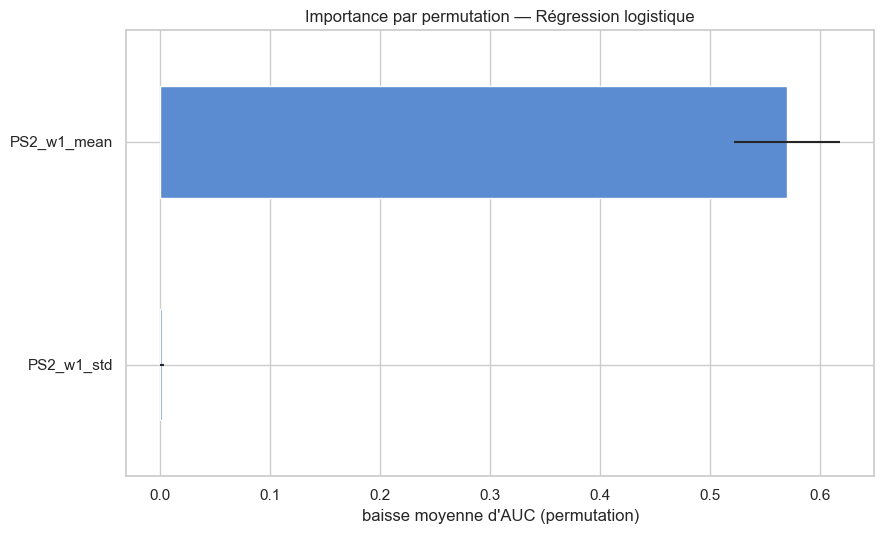

20 variables utilisées par le modèle final : ['PS2_skew', 'PS2_argmax_s', 'PS2_d_std', 'PS2_d_max', 'PS2_w1_mean', 'PS2_w1_std', 'PS2_band3_ratio', 'FS1_std', 'FS1_q75', 'FS1_q95', 'FS1_d_std', 'FS1_d_max', 'FS1_w1_mean', 'FS1_w1_std', 'FS1_w3_std', 'FS1_w8_mean', 'FS1_band0_ratio', 'FS1_band1_ratio', 'FS1_band2_ratio', 'FS1_band3_ratio']


,importance,std
PS2_w1_mean,0.5701,0.0484
PS2_w1_std,0.0014,0.0015


In [52]:
pi = permutation_importance(final_fitted, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns)
imp = imp[imp["importance"] > 0].sort_values("importance", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
imp["importance"].iloc[::-1].plot.barh(ax=ax, xerr=imp["std"].iloc[::-1], color="#5b8bd0")
ax.set_xlabel("baisse moyenne d'AUC (permutation)"); ax.set_title(f"Importance par permutation — {FINAL_NAME}")
plt.tight_layout(); savefig("importance_permutation"); plt.show()
selected = final_fitted.named_steps["select"] if hasattr(final_fitted, "named_steps") else None
if selected is not None:
    names_after_corr = final_fitted.named_steps["corr"].get_feature_names_out()
    kept = names_after_corr[selected.get_support()]
    print(f"{len(kept)} variables utilisées par le modèle final :", list(kept))
    RESULTS["nFinalFeatures"] = len(kept)
imp.round(4)

### 6.1 Analyse physique : l'instant de commutation de la valve

La variable dominante, `PS2_w1_mean`, est la pression moyenne entre 6 et 12 s, c'est-à-dire
autour de la remontée de pression visible vers 9,4 s sur la figure des profils moyens. On
mesure directement cet instant : premier instant après 5 s où PS2 dépasse 50 bar.

mean    std   min   max
jeu          valve                          
entraînement 73     9.667  0.007  9.66  9.70
             80     9.543  0.005  9.54  9.57
             90     9.442  0.004  9.44  9.46
             100    9.372  0.004  9.37  9.39
test         73     9.666  0.005  9.66  9.67
             80     9.540  0.000  9.54  9.54
             90     9.440  0.000  9.44  9.44
             100    9.370  0.000  9.37  9.37

valve,73,80,90,100
accumulator,,,,
90,9.669,9.544,9.443,9.371
100,9.665,9.543,9.442,9.373
115,9.669,9.544,9.443,9.373
130,9.665,9.542,9.441,9.372


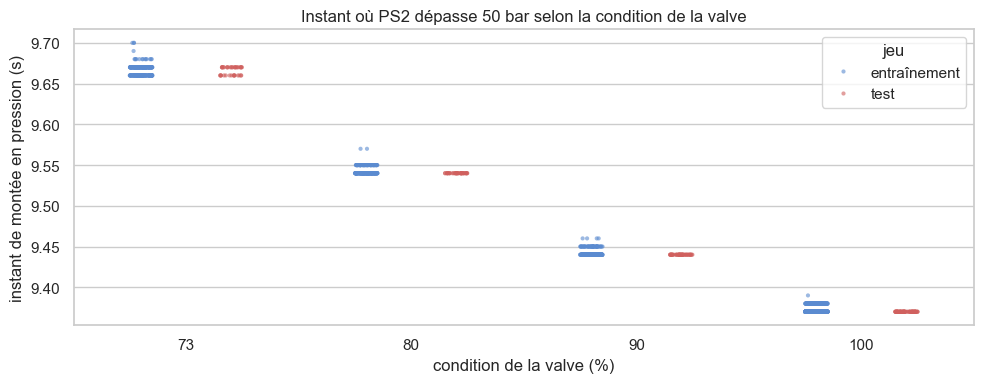

In [53]:
seg_start = 500  # 5 s
rise_time = pd.Series((np.argmax(ps2[:, seg_start:] > 50, axis=1) + seg_start) / 100.0, index=profile.index, name="t_montee_s")
rt = pd.DataFrame({"t_montee_s": rise_time, "valve": profile["valve"], "accumulator": profile["accumulator"],
                   "jeu": np.where(profile.index <= N_TRAIN, "entraînement", "test")})
display(rt.groupby(["jeu", "valve"])["t_montee_s"].agg(["mean", "std", "min", "max"]).round(3))
display(rt[rt["jeu"] == "entraînement"].groupby(["accumulator", "valve"])["t_montee_s"].mean().unstack().round(3))

fig, ax = plt.subplots(figsize=(10, 4))
sns.stripplot(data=rt, x="valve", y="t_montee_s", hue="jeu", dodge=True, size=3, alpha=.6, ax=ax, palette=["#5b8bd0", "#d0605e"])
ax.set_xlabel("condition de la valve (%)"); ax.set_ylabel("instant de montée en pression (s)")
ax.set_title("Instant où PS2 dépasse 50 bar selon la condition de la valve")
plt.tight_layout(); savefig("instant_commutation"); plt.show()

means = rt[rt["jeu"] == "entraînement"].groupby("valve")["t_montee_s"].mean()
RESULTS["riseHundred"] = f"{means[100]:.2f}"; RESULTS["riseNinety"] = f"{means[90]:.2f}"
RESULTS["riseEighty"] = f"{means[80]:.2f}"; RESULTS["riseSeventythree"] = f"{means[73]:.2f}"
RESULTS["delayNinetyMs"] = f"{1000 * (means[90] - means[100]):.0f}"

**Expérience a posteriori (ne remplace pas le modèle choisi en 4.1).** Un classifieur à
**une seule variable**, l'instant de montée en pression, est entraîné sur les 2000 premiers
cycles et évalué sur le test.

In [54]:
one = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))])
cv_one = cross_validate(one, rt[["t_montee_s"]].iloc[:N_TRAIN], y_train, cv=CV, scoring=["f1", "roc_auc"])
one.fit(rt[["t_montee_s"]].iloc[:N_TRAIN], y_train)
p_one = one.predict(rt[["t_montee_s"]].iloc[N_TRAIN:])
print(f"CV : F1={cv_one['test_f1'].mean():.4f}  AUC={cv_one['test_roc_auc'].mean():.4f}")
print(f"Test : accuracy={accuracy_score(y_test, p_one):.4f}  F1={f1_score(y_test, p_one):.4f}")
RESULTS["oneFeatTestAcc"] = accuracy_score(y_test, p_one); RESULTS["oneFeatTestFone"] = f1_score(y_test, p_one)

CV : F1=1.0000  AUC=1.0000
Test : accuracy=1.0000  F1=1.0000


## 7. Sauvegarde du modèle et export des résultats pour le rapport

In [55]:
MODEL_DIR = Path("../models") if Path("../models").exists() else Path("models"); MODEL_DIR.mkdir(exist_ok=True)
final_all = clone(best[FINAL_NAME]).fit(X_train, y_train)  # entraîné uniquement sur les 2000 premiers cycles
joblib.dump({"model": final_all, "name": FINAL_NAME, "features": list(X.columns), "n_train": N_TRAIN},
            MODEL_DIR / "modele_valve.joblib")
X.to_csv(MODEL_DIR / "features.csv.gz")  # utilisé par l'application web
profile.to_csv(MODEL_DIR / "profile.csv")
print("Modèle sauvegardé dans", MODEL_DIR / "modele_valve.joblib")

def tex_escape(s):
    return str(s).replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("{", r"\{").replace("}", r"\}")

def to_latex_table(df, path, fmt="{:.4f}"):
    cols = list(df.columns)
    lines = [r"\begin{tabular}{l" + "r" * len(cols) + "}", r"\toprule",
             " & ".join(["Modèle"] + [tex_escape(c) for c in cols]) + r" \\", r"\midrule"]
    for idx, *row in df.itertuples():  # itertuples conserve le type de chaque colonne (entiers)
        vals = [fmt.format(v) if isinstance(v, (float, np.floating)) else tex_escape(v) for v in row]
        lines.append(" & ".join([tex_escape(idx)] + vals) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    Path(path).write_text("\n".join(lines), encoding="utf-8")

rename = {"accuracy": "Accuracy", "precision": "Précision", "recall": "Rappel", "f1": "F1", "roc_auc": "AUC"}
to_latex_table(res_base[["accuracy", "precision", "recall", "f1", "roc_auc", "F1 train", "écart train-val (F1)"]]
               .rename(columns={**rename, "écart train-val (F1)": "Écart F1"}), TAB_DIR / "cv_base.tex", "{:.3f}")
to_latex_table(res_opt[["accuracy", "precision", "recall", "f1", "roc_auc", "F1 train", "écart train-val (F1)"]]
               .rename(columns={**rename, "écart train-val (F1)": "Écart F1"}), TAB_DIR / "cv_opt.tex", "{:.3f}")
to_latex_table(res_test.rename(columns=rename), TAB_DIR / "test.tex", "{:.3f}")
to_latex_table(tuning[["méthode", "combinaisons", "AUC avant", "AUC après", "temps (s)"]]
               .rename(columns={"méthode": "Méthode", "combinaisons": "Comb.", "temps (s)": "Temps (s)"}), TAB_DIR / "tuning.tex", "{:.3f}")
to_latex_table(rob, TAB_DIR / "robustesse.tex", "{:.3f}")
to_latex_table(by_valve.rename(columns={"cycles": "Cycles", "erreurs": "Erreurs", "taux_erreur": "Taux"}).rename(index=lambda v: f"valve {v} %"),
               TAB_DIR / "erreurs_valve.tex", "{:.3f}")
with open(TAB_DIR / "params.tex", "w", encoding="utf-8") as fh:
    fh.write("\\begin{tabular}{lp{11cm}}\n\\toprule\nModèle & Meilleurs hyperparamètres \\\\\n\\midrule\n")
    for name, row in tuning.iterrows():
        p = ", ".join(f"{k}={v}" for k, v in row["meilleurs paramètres"].items())
        fh.write(f"{tex_escape(name)} & \\texttt{{{tex_escape(p)}}} \\\\\n")
    fh.write("\\bottomrule\n\\end{tabular}\n")

def macro_name(k):
    return "res" + "".join(ch for ch in k if ch.isalpha())

with open(TAB_DIR / "resultats.tex", "w", encoding="utf-8") as fh:
    fh.write("% Fichier généré automatiquement par le notebook : ne pas modifier à la main\n")
    for k, v in RESULTS.items():
        if isinstance(v, (float, np.floating)):
            v = f"{v:.3f}" if abs(v) <= 1 else f"{v:.1f}"
        fh.write(f"\\newcommand{{\\{macro_name(k)}}}{{{tex_escape(v)}}}\n")
print(open(TAB_DIR / "resultats.tex", encoding="utf-8").read())

Modèle sauvegardé dans ../models/modele_valve.joblib
% Fichier généré automatiquement par le notebook : ne pas modifier à la main
\newcommand{\resnOutlierCycles}{331}
\newcommand{\restrainPosPct}{52.6}
\newcommand{\restestPosPct}{35.6}
\newcommand{\resnTest}{205}
\newcommand{\resnTestPos}{73}
\newcommand{\resnFeatures}{90}
\newcommand{\respctHighCorrPairs}{11.3}
\newcommand{\resnAfterCorr}{47}
\newcommand{\resnLNonZero}{13}
\newcommand{\reskDefault}{10}
\newcommand{\resfinalModel}{Régression logistique}
\newcommand{\resfinalCvAuc}{1.000}
\newcommand{\resfinalCvFone}{0.994}
\newcommand{\resfinalCvAcc}{0.994}
\newcommand{\restestAccuracy}{0.859}
\newcommand{\restestPrecision}{0.716}
\newcommand{\restestRecall}{1.000}
\newcommand{\restestFone}{0.834}
\newcommand{\restestRocauc}{1.000}
\newcommand{\restestTN}{103}
\newcommand{\restestFP}{29}
\newcommand{\restestFN}{0}
\newcommand{\restestTP}{73}
\newcommand{\resnTestErrors}{29}
\newcommand{\resnFinalFeatures}{20}
\newcommand{\resriseHundre

## Conclusion

Le notebook couvre l'ensemble de la méthodologie demandée : contrôle qualité des données,
binarisation de la cible, analyse de l'équilibre des classes et des corrélations,
extraction et sélection de variables, comparaison de neuf modèles (linéaires, à base
d'instances, arbres, probabiliste, SVM, ensembles), évaluation par validation croisée
stratifiée avec matrices de confusion et courbes ROC, analyse biais/variance par courbes
d'apprentissage, optimisation par Grid Search et Random Search, puis évaluation unique sur
les 205 cycles de test. Le modèle final est sauvegardé dans `models/modele_valve.joblib` et
utilisé par l'application web (`app/`).